In [1]:
import pandas as pd
import scanpy as sc
import numpy as np
import anndata as ad
import os
import colorcet as cc
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import harmonypy as hm
import scrublet as scr
import traceback
from collections import Counter
from sklearn.decomposition import PCA
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import re
from matplotlib.patches import Patch
from PIL import Image

# --- ADOBE ILLUSTRATOR COMPATIBILITY ---
# 42 is for TrueType fonts (editable text in Illustrator)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

# --- NOTEBOOK SETTINGS ---
%matplotlib inline

# Define Working Directory
working_dic = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/results/"
os.chdir(working_dic)

# --- SCANPY SETTINGS ---
sc.settings.verbosity = 1
sc.logging.print_header()

# Professional Plotting Parameters
# sc.set_figure_params( dpi=100,  dpi_save=300,  vector_friendly=True, format='pdf',  transparent=True, facecolor='white' )

# --- CUSTOM COLOR SCHEMES ---
# Your grey-to-blue gradient for feature plots
dimplot_color = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["#E5E5E5", "#4C4DB7"])

COND_ORDER = [
    "Control",
    "Prematurely-terminated",
    "3month-protocol",
    "6month-protocol",
    "PCMV/PRV",
    "Rejection",
]

COND_COLORS = {
    "Control": "#EFE48E",
    "3month-protocol": "skyblue",
    "6month-protocol": "#08528f",
    "Prematurely-terminated": "#C9B8D9",
    "PCMV/PRV": "#F0C096",
    "Rejection": "#E09E9E",
}


In [2]:
raw_lymph_sus = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/cleaned_raw_Lymph_sus_v5.h5ad')

Loaded: 125 nuclei  ×  53,826 genes
Conditions: {'Control': 71, 'Prematurely-terminated': 51, '6month-protocol': 2, 'Rejection': 1}


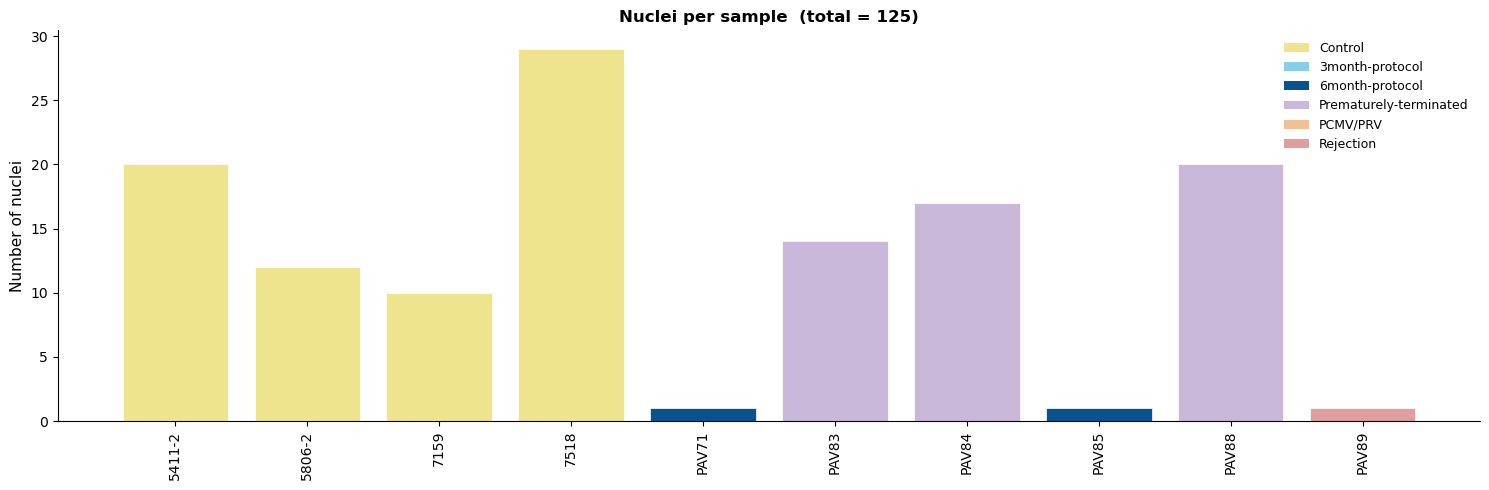

In [3]:

raw_lymph_sus = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/cleaned_raw_Lymph_sus_v5.h5ad')

adata = raw_lymph_sus.copy()
 
print(f"Loaded: {adata.n_obs:,} nuclei  ×  {adata.n_vars:,} genes")
print(f"Conditions: {adata.obs['Condition'].value_counts().to_dict()}")
 
# Cell count bar plot per sample
sample_meta = adata.obs[["Sample_ID", "Condition"]].drop_duplicates().set_index("Sample_ID")
counts      = adata.obs["Sample_ID"].value_counts().sort_index()
bar_colors  = [COND_COLORS.get(sample_meta.loc[s, "Condition"], "grey") for s in counts.index]
 
fig, ax = plt.subplots(figsize=(15, 5))
ax.bar(range(len(counts)), counts.values, color=bar_colors, edgecolor="white", linewidth=0.5)
ax.set_xticks(range(len(counts)))
ax.set_xticklabels(counts.index, rotation=90, fontsize=10)
ax.set_ylabel("Number of nuclei", fontsize=11)
ax.set_title(f"Nuclei per sample  (total = {adata.n_obs:,})", fontsize=12, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    handles=[Patch(facecolor=v, label=k) for k, v in COND_COLORS.items()],
    loc="upper right", frameon=False, fontsize=9
)
plt.tight_layout()
# plt.savefig(f"{OUTPUT_DIR}/01_cell_counts_per_sample.pdf", dpi=150, bbox_inches="tight")
plt.show()
# print("Saved: 01_cell_counts_per_sample")



# Preprocessing

In [4]:
raw_lymph_sus = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/cleaned_raw_Lymph_sus_v5.h5ad')

adata = raw_lymph_sus.copy()
 
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
 
# Store normalised + log-transformed counts for all genes.
# .raw is used later for differential expression (all genes, not just HVGs).
adata.raw = adata.copy()
print(f".raw stored: {adata.raw.shape[0]:,} nuclei × {adata.raw.shape[1]:,} genes")


.raw stored: 125 nuclei × 53,826 genes


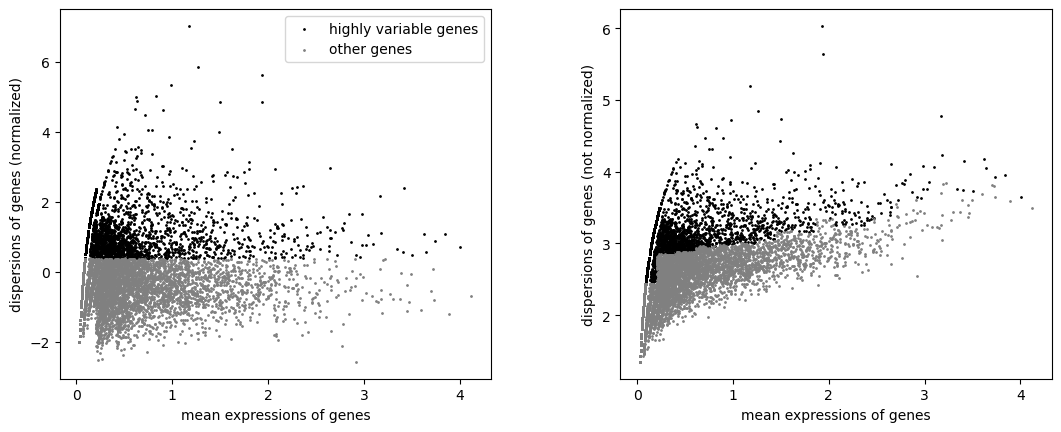

Number of highly variable genes (HVGs): 3000
Subsetting complete. New shape: (125, 3000)


In [5]:
# 1. Identify highly variable genes 

sc.pp.highly_variable_genes(
    adata, 
    n_top_genes=3000, 
    subset=False, 
    flavor='seurat'
)

# 2. Plot highly variable genes
# This will highlight the top 5000 in red
sc.pl.highly_variable_genes(adata)

# 3. Verify the count
num_hvgs = adata.var['highly_variable'].sum()
print(f"Number of highly variable genes (HVGs): {num_hvgs}")

# 4. Subset to HVGs for downstream analysis (PCA/Harmony)
# We keep a copy of the full object if needed, but subset for speed
adata_hvg = adata[:, adata.var['highly_variable']].copy()

print(f"Subsetting complete. New shape: {adata_hvg.shape}")


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


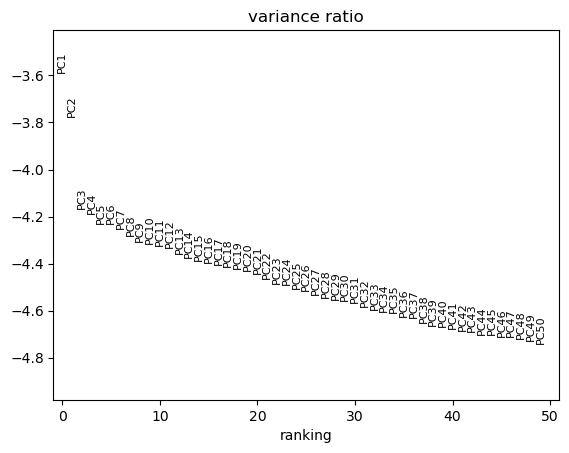

/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [6]:
# 2. Scale the data (z-score normalization)
sc.pp.scale(adata_hvg, max_value=10)  # max_value=10 clips extreme outliers

# 3. Run PCA
sc.tl.pca(adata_hvg, n_comps=50, svd_solver='arpack')  # Adjust n_comps as needed

# 4. (Optional) Plot variance explained
sc.pl.pca_variance_ratio(adata_hvg, log=True, n_pcs=50)

adata_hvg.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/Lymph_sus_hvg_xeno_v5.h5ad')


In [7]:
pca_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/Lymph_sus_hvg_xeno_v5.h5ad')


# Harmony

In [8]:
pca_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/Lymph_sus_hvg_xeno_v5.h5ad')


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


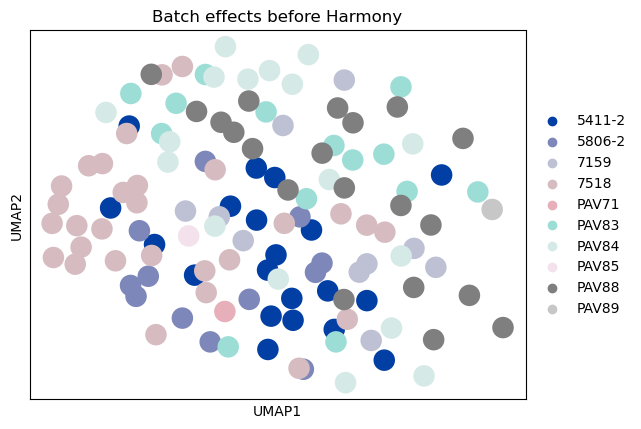

In [9]:
# Checking batch effects before Harmony
sc.pp.neighbors(pca_adata, random_state=10, n_neighbors=15, n_pcs=50)

# Perform UMAP
sc.tl.umap(pca_adata)

# Plot UMAP colored by sample (batch) and save it
sc.pl.umap (pca_adata, color=['Sample_ID'],  title='Batch effects before Harmony')

In [10]:
# Subset PCA to exactly the PCs used for neighbours
pca_matrix = pca_adata.obsm["X_pca"][:, :50].copy()
print(f"PCA matrix passed to Harmony: {pca_matrix.shape}")

ho = hm.run_harmony(
    pca_matrix,
    pca_adata.obs,
    vars_use="Sample_ID",
    # max_iter_harmony=20,
    epsilon_harmony=-float('Inf'), # FORCE RUN: Ignore early convergence
    epsilon_cluster=-float('Inf'), # FORCE RUN: Ignore early convergence
    
    random_state=10,
    verbose=True         # Prints iteration + objective value so you can
                         # see exactly when and why it stops
)
 
pca_adata.obsm["X_pca_harmony"] = ho.Z_corr.T
 
print(f"\nHarmony embedding stored in obsm['X_pca_harmony']")
print(f"Shape: {pca_adata.obsm['X_pca_harmony'].shape}") 
 

2026-06-26 12:47:19,607 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-06-26 12:47:19,764 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-06-26 12:47:19,765 - harmonypy - INFO - Iteration 1 of 10
2026-06-26 12:47:19,786 - harmonypy - INFO - Iteration 2 of 10
2026-06-26 12:47:19,805 - harmonypy - INFO - Iteration 3 of 10


PCA matrix passed to Harmony: (125, 50)


2026-06-26 12:47:19,824 - harmonypy - INFO - Iteration 4 of 10
2026-06-26 12:47:19,843 - harmonypy - INFO - Iteration 5 of 10
2026-06-26 12:47:19,862 - harmonypy - INFO - Iteration 6 of 10
2026-06-26 12:47:19,881 - harmonypy - INFO - Iteration 7 of 10
2026-06-26 12:47:19,899 - harmonypy - INFO - Iteration 8 of 10
2026-06-26 12:47:19,918 - harmonypy - INFO - Iteration 9 of 10
2026-06-26 12:47:19,937 - harmonypy - INFO - Iteration 10 of 10
2026-06-26 12:47:19,956 - harmonypy - INFO - Stopped before convergence



Harmony embedding stored in obsm['X_pca_harmony']
Shape: (125, 50)


In [11]:
pca_adata.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/hm_lymph_sus_xeno_v5.h5ad')


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [12]:
hm_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/hm_lymph_sus_xeno_v5.h5ad')


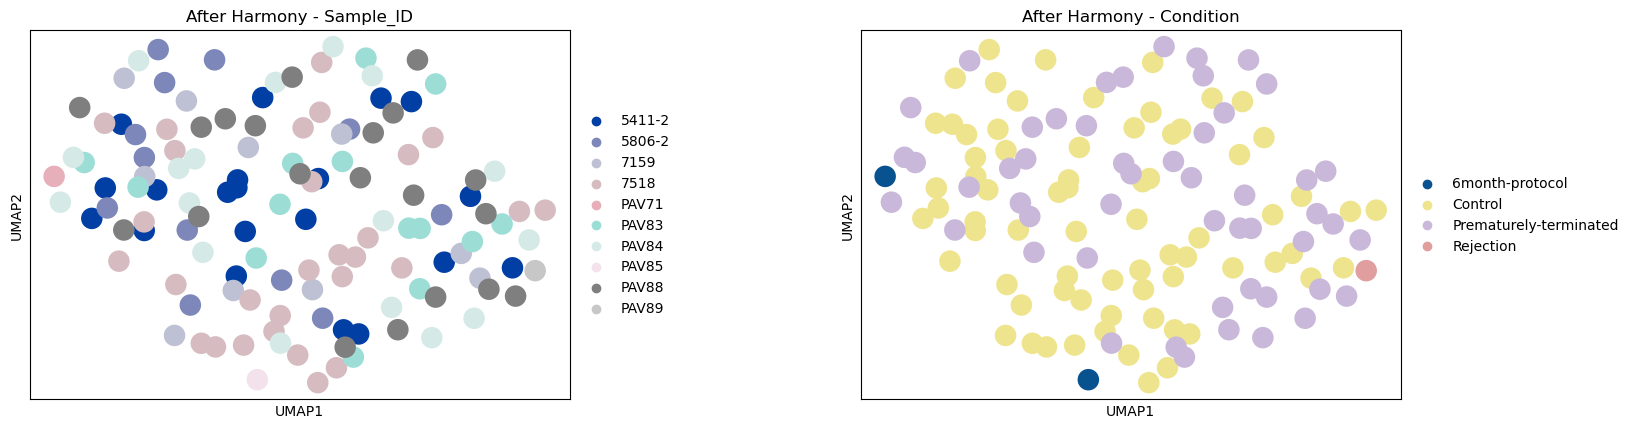

In [13]:
# Compute neighbors using Harmony embeddings
sc.pp.neighbors(
    hm_adata, 
    use_rep='X_pca_harmony',  # This is the key - use Harmony instead of PCA
    n_neighbors=15, 
    n_pcs=50,
    random_state=10
)

# Recompute UMAP based on Harmony
sc.tl.umap(hm_adata, random_state=10)

# Visualize - should show reduced batch effects
sc.pl.umap(
    hm_adata, color=['Sample_ID', 'Condition'],  ncols=2, wspace = 0.4,  title=['After Harmony - Sample_ID', 'After Harmony - Condition']
)

In [14]:
# 1. Compute Neighbors (Graph building)
sc.pp.neighbors(
    hm_adata, 
    use_rep='X_pca_harmony', 
    n_neighbors=15, 
    n_pcs=50,
    random_state=10
)

# 2. Run UMAP with min_dist and spread (Embedding/Visualization)
sc.tl.umap(
    hm_adata, 
    min_dist=0.5, 
    spread=0.7, 
    random_state=10
)

# 3. Run Leiden Clustering (Community detection)
resolutions = [
    0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1 , 1.2 ,1.3, 1.4
              ]

for res in resolutions:
    # Formats key cleanly (e.g., leiden_03, leiden_04)
    key = f"leiden_{str(res).replace('.', '')}"
    print(f"Running Leiden clustering at resolution {res} -> stored in {key}")
    
    sc.tl.leiden(
        hm_adata, 
        resolution=res, 
        key_added=key, 
        random_state=10
    )

print("✓ UMAP and Leiden clustering complete.")

Running Leiden clustering at resolution 0.3 -> stored in leiden_03
Running Leiden clustering at resolution 0.4 -> stored in leiden_04
Running Leiden clustering at resolution 0.5 -> stored in leiden_05
Running Leiden clustering at resolution 0.6 -> stored in leiden_06
Running Leiden clustering at resolution 0.7 -> stored in leiden_07
Running Leiden clustering at resolution 0.8 -> stored in leiden_08
Running Leiden clustering at resolution 0.9 -> stored in leiden_09
Running Leiden clustering at resolution 1.0 -> stored in leiden_10
Running Leiden clustering at resolution 1.1 -> stored in leiden_11
Running Leiden clustering at resolution 1.2 -> stored in leiden_12
Running Leiden clustering at resolution 1.3 -> stored in leiden_13
Running Leiden clustering at resolution 1.4 -> stored in leiden_14
✓ UMAP and Leiden clustering complete.


/tmp/ipykernel_507465/4099340311.py:28: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


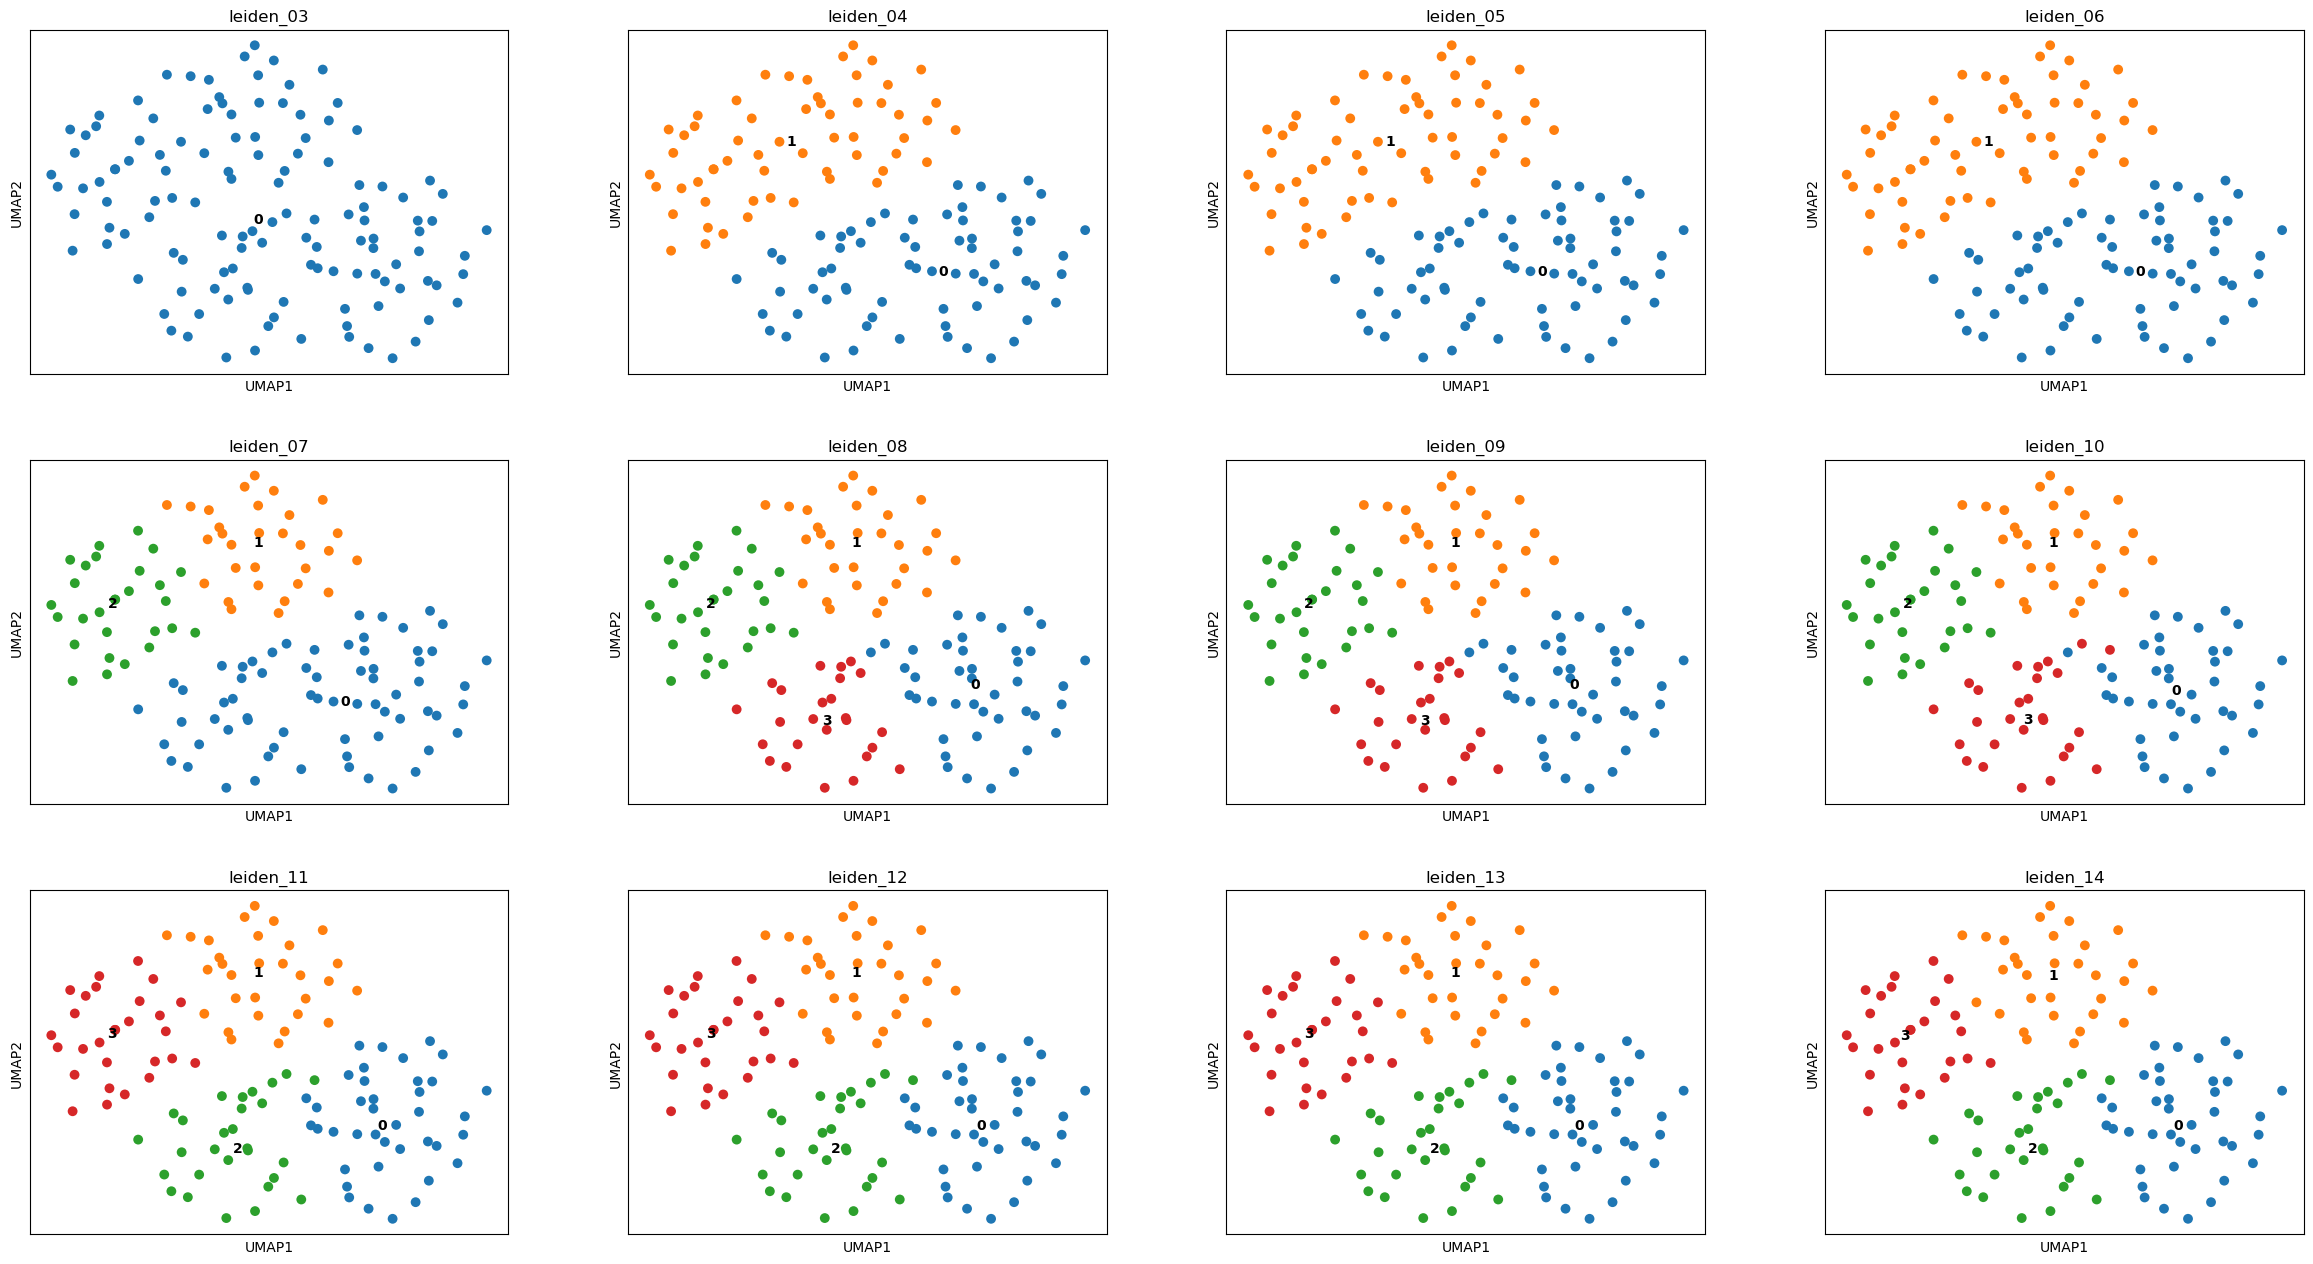

In [15]:

sc.pl.umap( hm_adata, color=[  "leiden_03", "leiden_04", "leiden_05" , "leiden_06" , "leiden_07", "leiden_08" , "leiden_09", "leiden_10", "leiden_11" , "leiden_12", "leiden_13", "leiden_14" ],
            legend_loc="on data",  size=200)


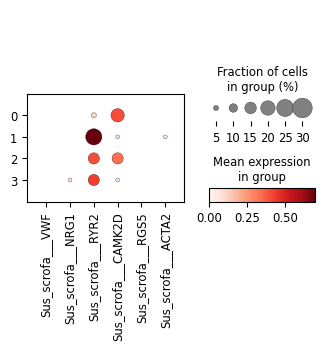

In [17]:
sc.pl.dotplot(
    hm_adata, 
    var_names=[

# 'Sus_scrofa___FN1', 
        # 'Sus_scrofa___TTN',
        'Sus_scrofa___VWF', 'Sus_scrofa___NRG1', 'Sus_scrofa___RYR2', 'Sus_scrofa___CAMK2D', 
         'Sus_scrofa___RGS5', 
         'Sus_scrofa___ACTA2'


        
    ], 
    groupby='leiden_12', 
    # standard_scale='var',  # Scales expression from 0 to 1 for better comparison
    cmap='Reds', 
    # standard_scale = 'var',
    # use_raw = True

)
    

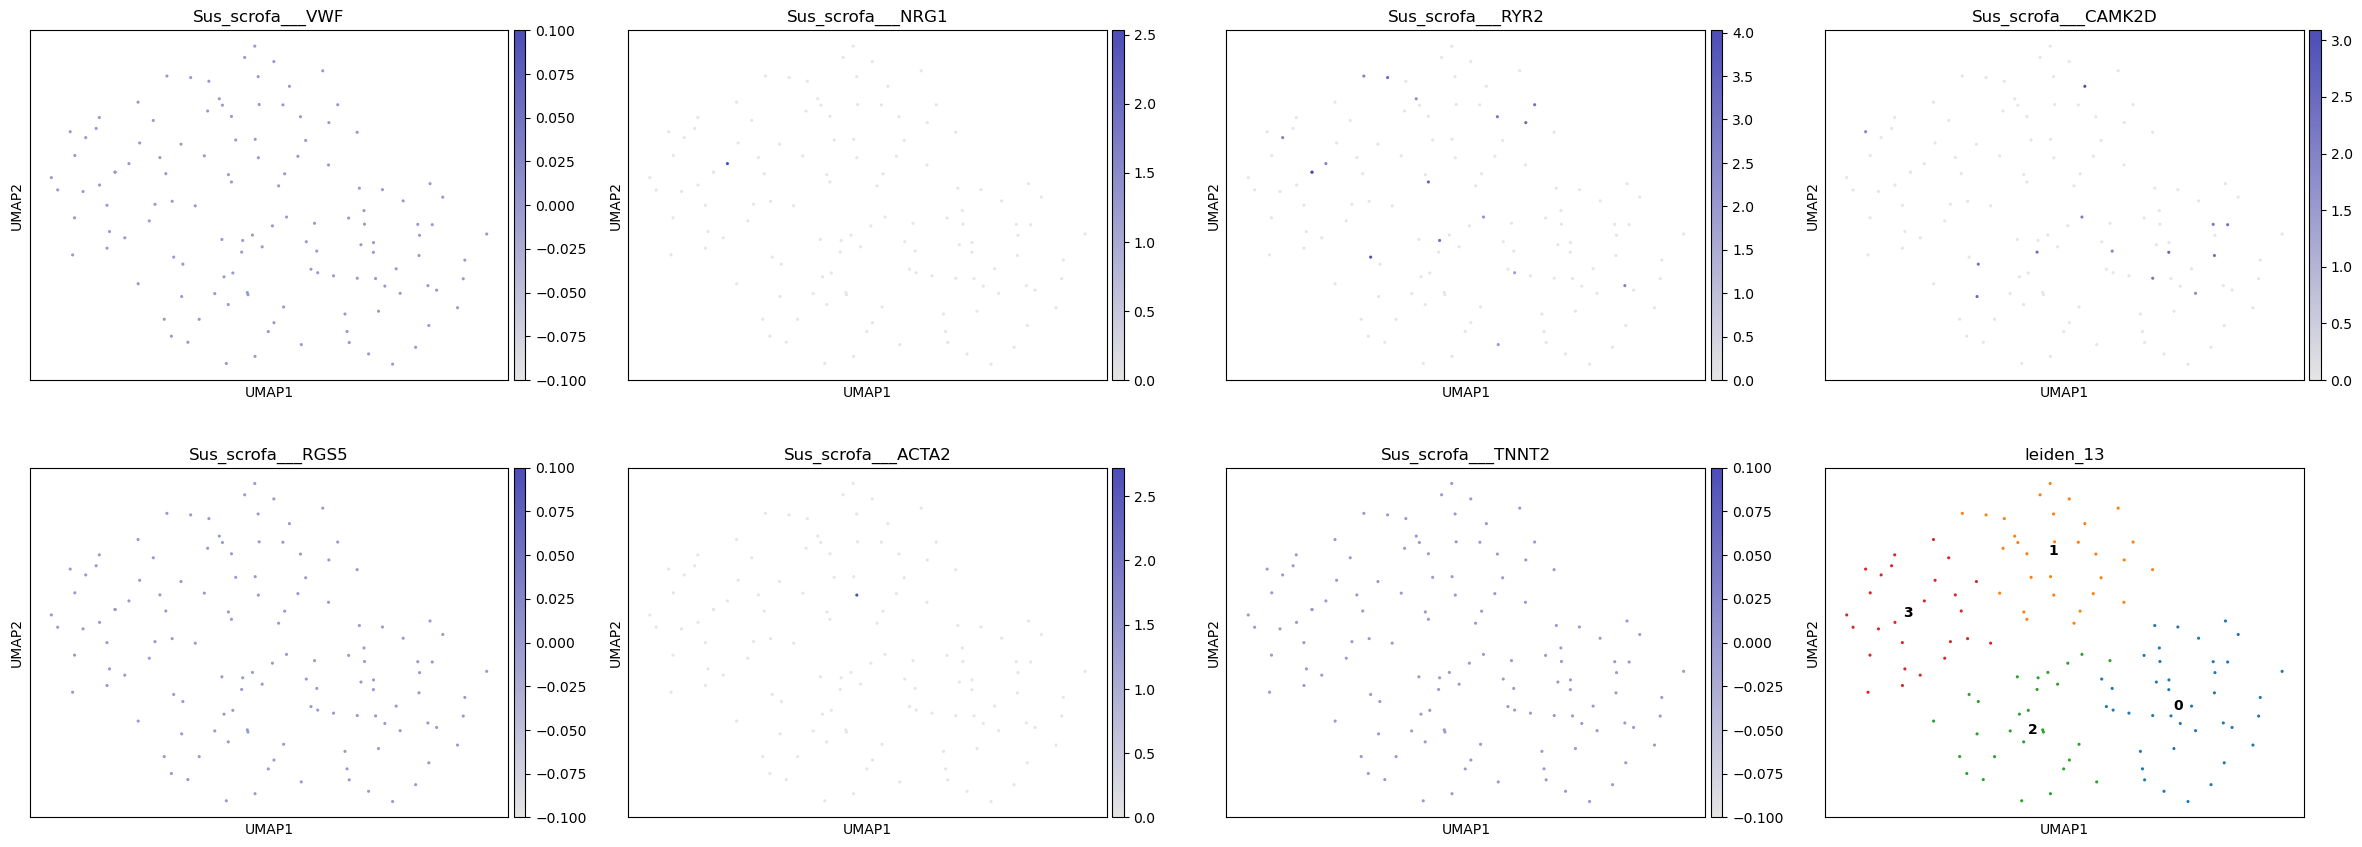

In [18]:

sc.pl.umap( hm_adata, color=[  'Sus_scrofa___VWF', 'Sus_scrofa___NRG1', 'Sus_scrofa___RYR2', 'Sus_scrofa___CAMK2D', 
         'Sus_scrofa___RGS5', 
         'Sus_scrofa___ACTA2', "Sus_scrofa___TNNT2", "leiden_13" ], cmap = dimplot_color,
            legend_loc="on data",  size=20)


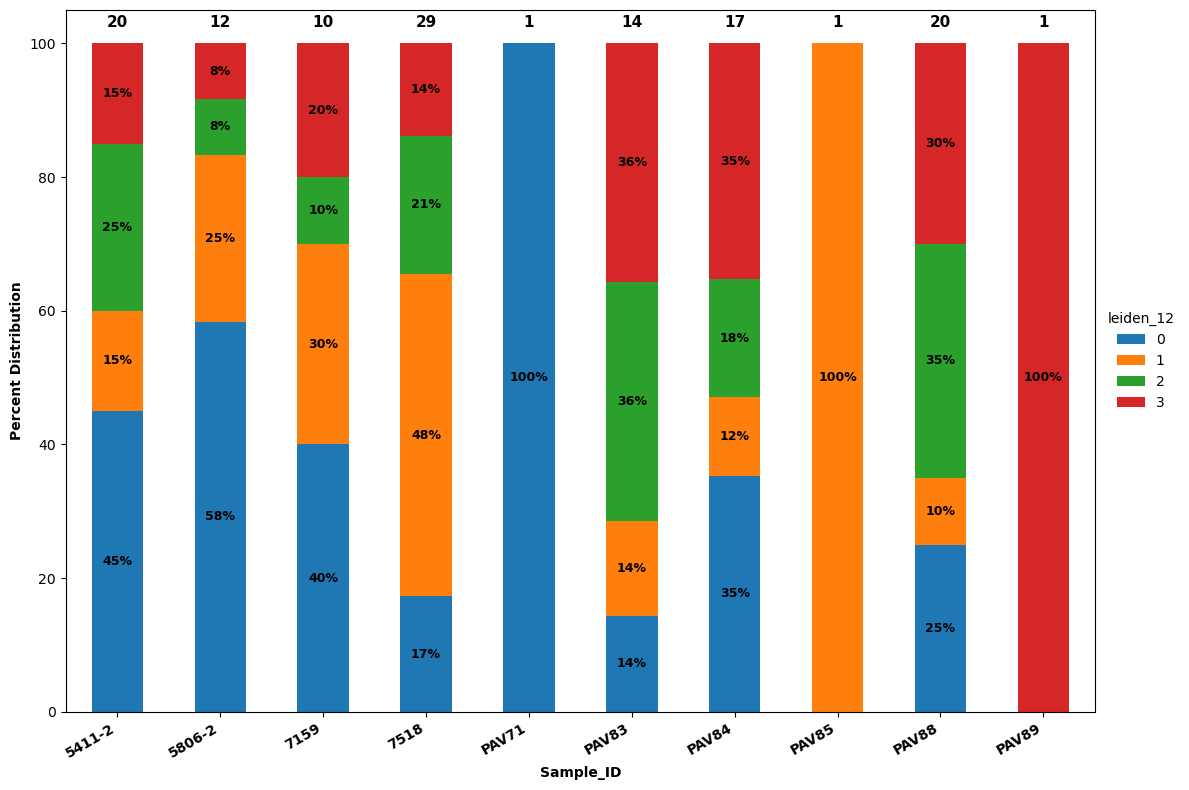

In [19]:
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

def stacked_barplot(adata, xaxis, stack, xaxis_label, legend_label, xaxis_rotation=30, figsize=(8, 6), percent=True):
    
    # 1. Prepare data
    crosstab = pd.crosstab(adata.obs[xaxis], adata.obs[stack])
    # Ensure the order of bars matches the state_order defined in your categorical data
    crosstab = crosstab[adata.obs[stack].cat.categories]
    tmp = crosstab.sum(axis=1)
    ax_data = crosstab.apply(lambda r: r/r.sum()*100, axis=1)
    
    # 2. Get colors from object
    colors = adata.uns.get(f"{stack}_colors", sc.pl.palettes.default_102[:len(ax_data.columns)])
    
    # 3. Plot
    fig, ax = plt.subplots(figsize=figsize)
    ax_plot = ax_data.plot.bar(stacked=True, rot=0, color=colors, ax=ax)
    
    # 4. Labels and Legend
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), title=legend_label, frameon=False)
    plt.xlabel(xaxis_label, fontweight="bold")
    plt.ylabel('Percent Distribution', fontweight="bold")
    
    # 5. Percentage labels inside bars
    if percent:
        for rec in ax_plot.patches:
            height = rec.get_height()
            if height > 3: # Only label if bar is significant
                ax_plot.text(rec.get_x() + rec.get_width() / 2, 
                             rec.get_y() + height / 2, 
                             f"{height:.0f}%",
                             ha='center', va='center', fontsize=9, weight='bold')
    
    # 6. FIX: Pin labels to the center of each bar
    # Get the center positions of the bars
    bar_positions = [patch.get_x() + patch.get_width() / 2 for patch in ax.patches[:len(ax_data.index)]]
    
    ax.set_xticks(bar_positions)
    ax.set_xticklabels(ax_data.index, rotation=xaxis_rotation, ha='right', fontweight='bold')
    
    # Add total cell counts exactly at the top of each bar group
    for i, pos in enumerate(bar_positions):
        ax.text(pos, 102, str(int(tmp.iloc[i])), ha='center', va='bottom', fontsize=11, weight='bold')
    
    ax.grid(False)
    plt.margins(x=0.05) # Add small buffer so labels don't get cut off
    plt.tight_layout()
    plt.show()

# Run the function
stacked_barplot(
    hm_adata, 
    xaxis='Sample_ID', 
    stack='leiden_12', 
    xaxis_label='Sample_ID', 
    legend_label='leiden_12', 
    xaxis_rotation=30, 
    figsize=(12, 8), 
    percent=True
)

# DEA

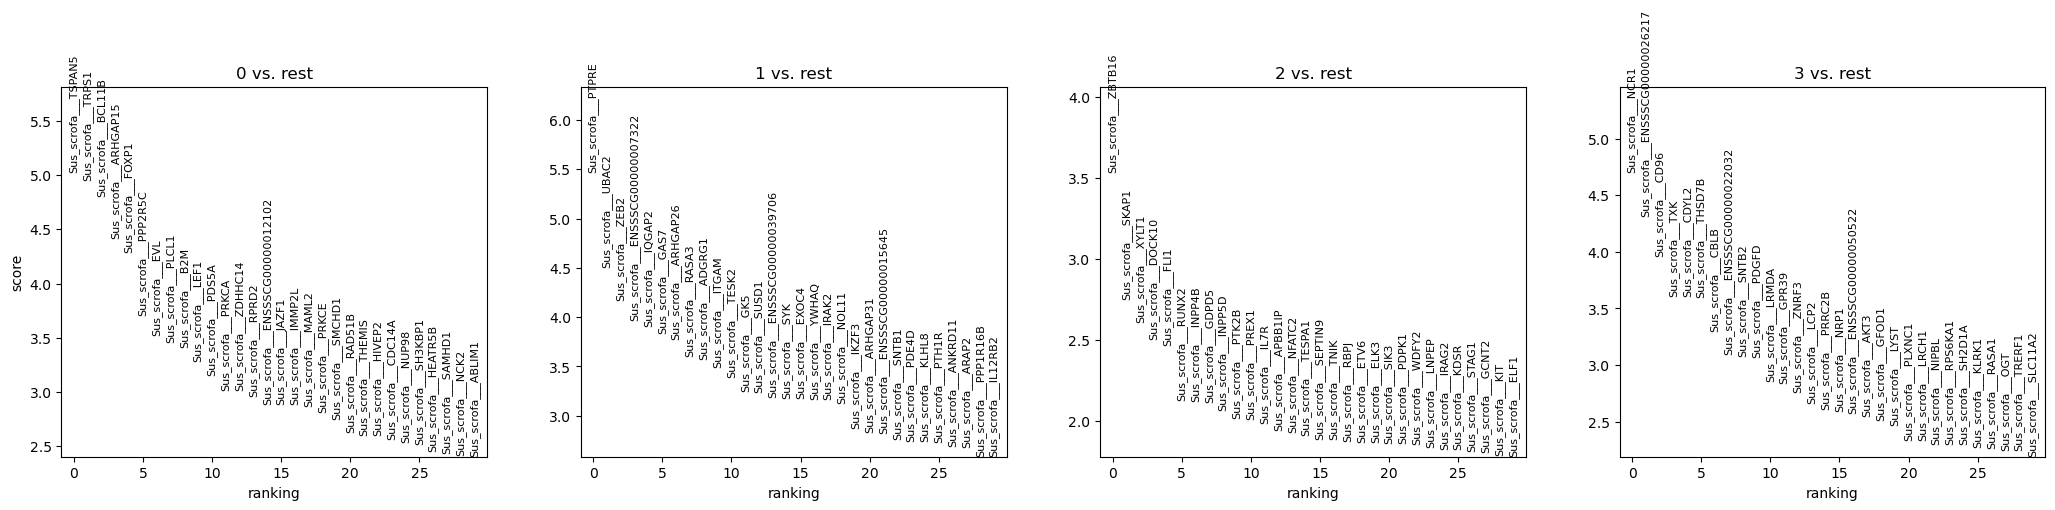

/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [20]:
# Perform differential expression to find marker genes for each cluster using Wilcoxon test on raw data
sc.tl.rank_genes_groups(hm_adata, 'leiden_12', method='wilcoxon', key_added='wilcoxon', use_raw=True)

# Visualize the top marker genes for each cluster
sc.pl.rank_genes_groups(hm_adata, key='wilcoxon', n_genes=30, sharey=False)

hm_adata.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/dea_Lymph_sus_xeno_v5.h5ad')


In [11]:
dea_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/dea_Lymph_sus_xeno_v5.h5ad')


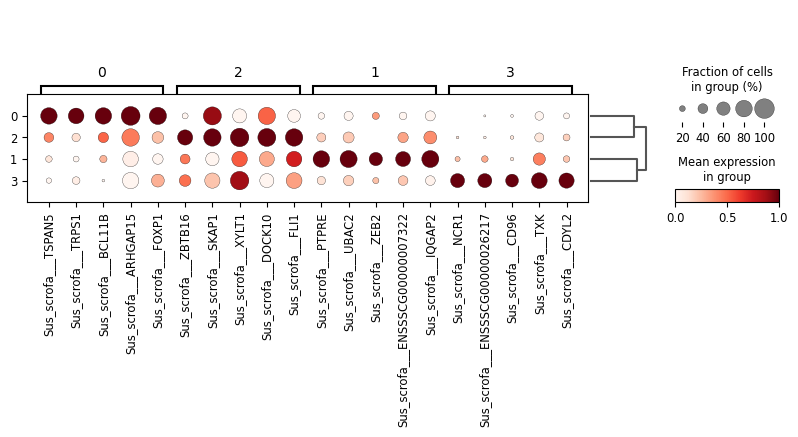

In [22]:
%matplotlib inline
sc.pl.rank_genes_groups_dotplot(dea_adata, key="wilcoxon", n_genes=5, standard_scale="var"
                                # , cmap="coolwarm", vmin= -1
                               )


In [23]:
import pandas as pd
import os

de_key = 'wilcoxon' 
results = dea_adata.uns[de_key]
clusters = results['names'].dtype.names  

output_dir = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/results/DEGs'
os.makedirs(output_dir, exist_ok=True)

for clust in clusters:
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    # Optional: Sort by Wilcoxon score, descending (highest first)
    df = df.sort_values('score', ascending=False)
    # Save to CSV
    df.to_csv(f"{output_dir}/Cluster_{clust}_DEGs.csv", index=False)



In [25]:
import os
import pandas as pd

# 1. Setup paths
base_results_dir = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/results/DEGs'
sig_output_dir = os.path.join(base_results_dir, "significant_DEGs")
os.makedirs(sig_output_dir, exist_ok=True)

# 2. Thresholds
P_ADJ_CUTOFF = 0.05
LFC_CUTOFF = 0.5

print(f"Filtering DEGs: pval_adj < {P_ADJ_CUTOFF} and |logfoldchange| > {LFC_CUTOFF}")

# 3. Process each cluster's results from your previous loop
# Using the 'clusters' variable from your previous code block
for clust in clusters:
    # Extract data from the scanpy results object
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    # Create the DataFrame
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    
    # 4. Apply strict filtering
    # Filtering for p-adj AND (|LFC| > 0.75)
    sig_df = df[
        (df['pval_adj'] < P_ADJ_CUTOFF) & 
        ((df['logfoldchange'] > LFC_CUTOFF) | (df['logfoldchange'] < -LFC_CUTOFF))
    ].copy()
    
    # Sort by logfoldchange descending
    sig_df = sig_df.sort_values('logfoldchange', ascending=False)
    
    # 5. Save if there are significant genes found
    if not sig_df.empty:
        output_file = f"{sig_output_dir}/Significant_Cluster_{clust}_DEGs.csv"
        sig_df.to_csv(output_file, index=False)
        print(f"  Cluster {clust}: Saved {len(sig_df)} significant DEGs.")
    else:
        print(f"  Cluster {clust}: No genes met the significance criteria.")

print("\nAll significant files saved in:", sig_output_dir)

Filtering DEGs: pval_adj < 0.05 and |logfoldchange| > 0.5
  Cluster 0: Saved 3 significant DEGs.
  Cluster 1: Saved 1 significant DEGs.
  Cluster 2: No genes met the significance criteria.
  Cluster 3: No genes met the significance criteria.

All significant files saved in: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/results/DEGs/significant_DEGs


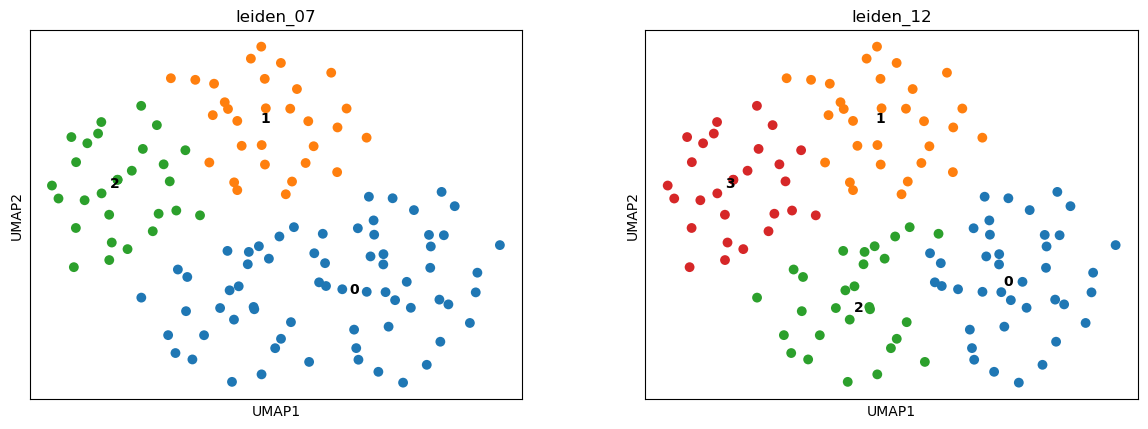

In [27]:

sc.pl.umap( hm_adata, color=[  "leiden_07" , "leiden_12"],
            legend_loc="on data",  size=200)


In [39]:
dea_adata.var

,gene_ids,feature_types,genome,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,highly_variable,means,dispersions,dispersions_norm,mean,std
Papio_anubis_MIER1,Papio_anubis_ENSPANG00000022218,Gene Expression,Papio_anubis,5658,0.026616,97.844686,6987,True,0.135571,2.898605,1.372901,0.023618,0.264056
Papio_anubis_LYST,Papio_anubis_ENSPANG00000016715,Gene Expression,Papio_anubis,6244,0.046127,97.621460,12109,True,0.120265,2.770990,1.095663,0.022654,0.253276
Papio_anubis_RAP1A,Papio_anubis_ENSPANG00000013352,Gene Expression,Papio_anubis,4740,0.025713,98.194382,6750,True,0.144134,2.964234,1.515476,0.024116,0.269629
Papio_anubis_PATJ,Papio_anubis_ENSPANG00000016676,Gene Expression,Papio_anubis,793,0.003505,99.697921,920,True,0.095083,2.523232,0.557420,0.020803,0.232585
Papio_anubis_MAP7D1,Papio_anubis_ENSPANG00000006397,Gene Expression,Papio_anubis,945,0.003798,99.640019,997,True,0.218853,3.420380,1.766604,0.027620,0.308806
...,...,...,...,...,...,...,...,...,...,...,...,...,...
Sus_scrofa___NP_001090939.1,Sus_scrofa___NP_001090939.1,Gene Expression,Sus_scrofa,7068,0.029713,97.307572,7800,True,0.175891,3.179655,1.983469,0.025763,0.288043
Sus_scrofa___ENSSSCG00000012257,Sus_scrofa___ENSSSCG00000012257,Gene Expression,Sus_scrofa,13025,0.104924,95.038360,27544,True,0.103451,2.611831,0.749898,0.021461,0.239945
Sus_scrofa___ENSSSCG00000008832,Sus_scrofa___ENSSSCG00000008832,Gene Expression,Sus_scrofa,21833,0.101035,91.683110,26523,True,0.170080,3.143073,1.903995,0.025483,0.284903
Sus_scrofa___ENSSSCG00000016737,Sus_scrofa___ENSSSCG00000016737,Gene Expression,Sus_scrofa,11590,0.050614,95.584997,13287,True,0.310315,2.861659,0.407134,0.064354,0.418827


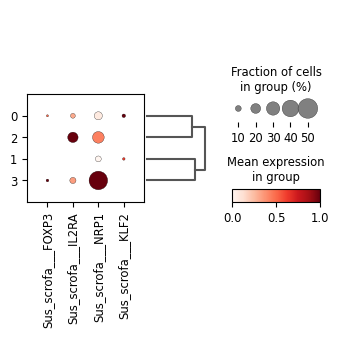

In [53]:
import scanpy as sc
import matplotlib.pyplot as plt

# 1. Define your marker gene list
marker_genes = [
    # 'Sus_scrofa___CD3E', 'Sus_scrofa___CD4', 'Sus_scrofa___CD8A',           # Lineage
    # 'Sus_scrofa___LEF1', 'Sus_scrofa___TCF7', 'Sus_scrofa___CCR7',          # Naïve markers
    # 'Sus_scrofa___FOXP3', 'Sus_scrofa___IL2RA', 
'Sus_scrofa___FOXP3', 'Sus_scrofa___IL2RA', 'Sus_scrofa___NRP1', 'Sus_scrofa___KLF2', 

]

# 2. Ensure your leiden resolution is set
# We use the 'leiden_12' you mentioned
sc.tl.dendrogram(dea_adata, groupby='leiden_12')

# 3. Create the DotPlot with Dendrogram
sc.pl.dotplot(
    dea_adata, 
    marker_genes, 
    groupby='leiden_12', 
    dendrogram=True, 
    standard_scale='var', 
    color_map='Reds'
)

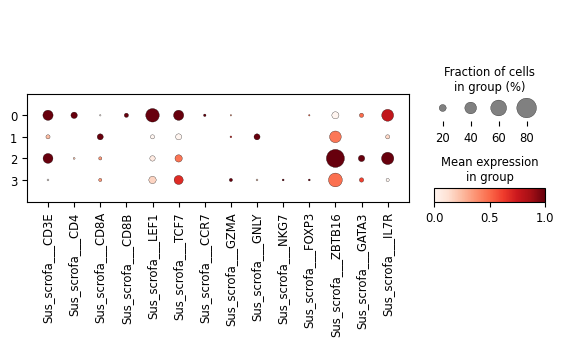

In [33]:
sc.pl.dotplot(
    dea_adata, 
    var_names=[
        # Lineage Markers
        'Sus_scrofa___CD3E', 'Sus_scrofa___CD4', 'Sus_scrofa___CD8A', 'Sus_scrofa___CD8B',
        
        # Naïve / Resting Markers
        'Sus_scrofa___LEF1', 'Sus_scrofa___TCF7', 'Sus_scrofa___CCR7',
        
        # Effector / Cytotoxic Markers
        'Sus_scrofa___GZMA',  'Sus_scrofa___GNLY', 'Sus_scrofa___NKG7',
        
        # NKT / Treg / ILC / Innate-like Markers
        'Sus_scrofa___FOXP3', 'Sus_scrofa___ZBTB16', 'Sus_scrofa___GATA3', 'Sus_scrofa___IL7R'
    ], 
    groupby='leiden_12', 
    standard_scale='var',  # Highly recommended for comparing disparate gene expression ranges
    cmap='Reds', 
    use_raw=True
)

# Annotation

In [6]:
import os
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
sc.settings.set_figure_params(dpi=300, dpi_save=300)
# 42 is for TrueType fonts (editable text in Illustrator)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42


# ---------------------------
# PATHS & SETUP
# ---------------------------
RESULTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/results"
OBJECTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(OBJECTS_DIR, exist_ok=True)

sc.settings.figdir = RESULTS_DIR
sc.settings.autosave = False
sc.settings.set_figure_params(dpi=300)

dea_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/dea_Lymph_sus_xeno_v5.h5ad')

# ---------------------------
# ANNOTATION (leiden_12)
# ---------------------------
# Cluster 0 & 2: Naive CD4T
# Cluster 1 & 3: Cytox NK
cluster_annotation = {
    '0': 'Naive_CD4T_sus',
    '1': 'CD56_NK_sus',
    '2': 'Naive_CD4T_sus',
    '3': 'CD56_NK_sus'
}

# Ensure cluster column is string
dea_adata.obs['leiden_12'] = dea_adata.obs['leiden_12'].astype(str)

# Map annotations
dea_adata.obs['cell_state'] = dea_adata.obs['leiden_12'].map(cluster_annotation)

# Safety check for unmapped cells
n_missing = dea_adata.obs['cell_state'].isna().sum()
print(f"cell_state missing (NaN) for {n_missing} cells")

# ---------------------------
# CATEGORICAL ORDERING
# ---------------------------
state_order = ['Naive_CD4T_sus', 'CD56_NK_sus']

present_states = [s for s in state_order if s in dea_adata.obs["cell_state"].unique()]

dea_adata.obs["cell_state"] = pd.Categorical(
    dea_adata.obs["cell_state"],
    categories=present_states,
    ordered=True
)

# ---------------------------
# COLORS
# ---------------------------
cell_state_colors = {
    "Naive_CD4T_sus": "#1f77b4", # Blue
    "CD56_NK_sus":   "#E69F00"  # Red
}

dea_adata.uns["cell_state_colors"] = [
    cell_state_colors[s] for s in dea_adata.obs["cell_state"].cat.categories
]

# ---------------------------
# PLOTS
# ---------------------------
plot_kwargs = dict(
    frameon=False,
    size=200,
    alpha=0.7,
    legend_loc="right margin",
    legend_fontsize=10,
    legend_fontweight="bold",
    legend_fontoutline=1,
)

with plt.rc_context({"figure.figsize": (5, 3)}):
    sc.pl.umap(
        dea_adata,
        color=["cell_state"],
        **plot_kwargs,
        save="_Annotated_Lymphoid_sus_v5_UMAP.pdf",
        show=False
    )

# ---------------------------
# SAVE
# ---------------------------
out_h5ad = os.path.join(OBJECTS_DIR, "Annotated_Lymph_sus_v5.h5ad")
dea_adata.write(out_h5ad)
print(f"\nSaved annotated object to: {out_h5ad}")

cell_state missing (NaN) for 0 cells

Saved annotated object to: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/Annotated_Lymph_sus_v5.h5ad


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [13]:
annotated_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/Annotated_Lymph_sus_v5.h5ad')

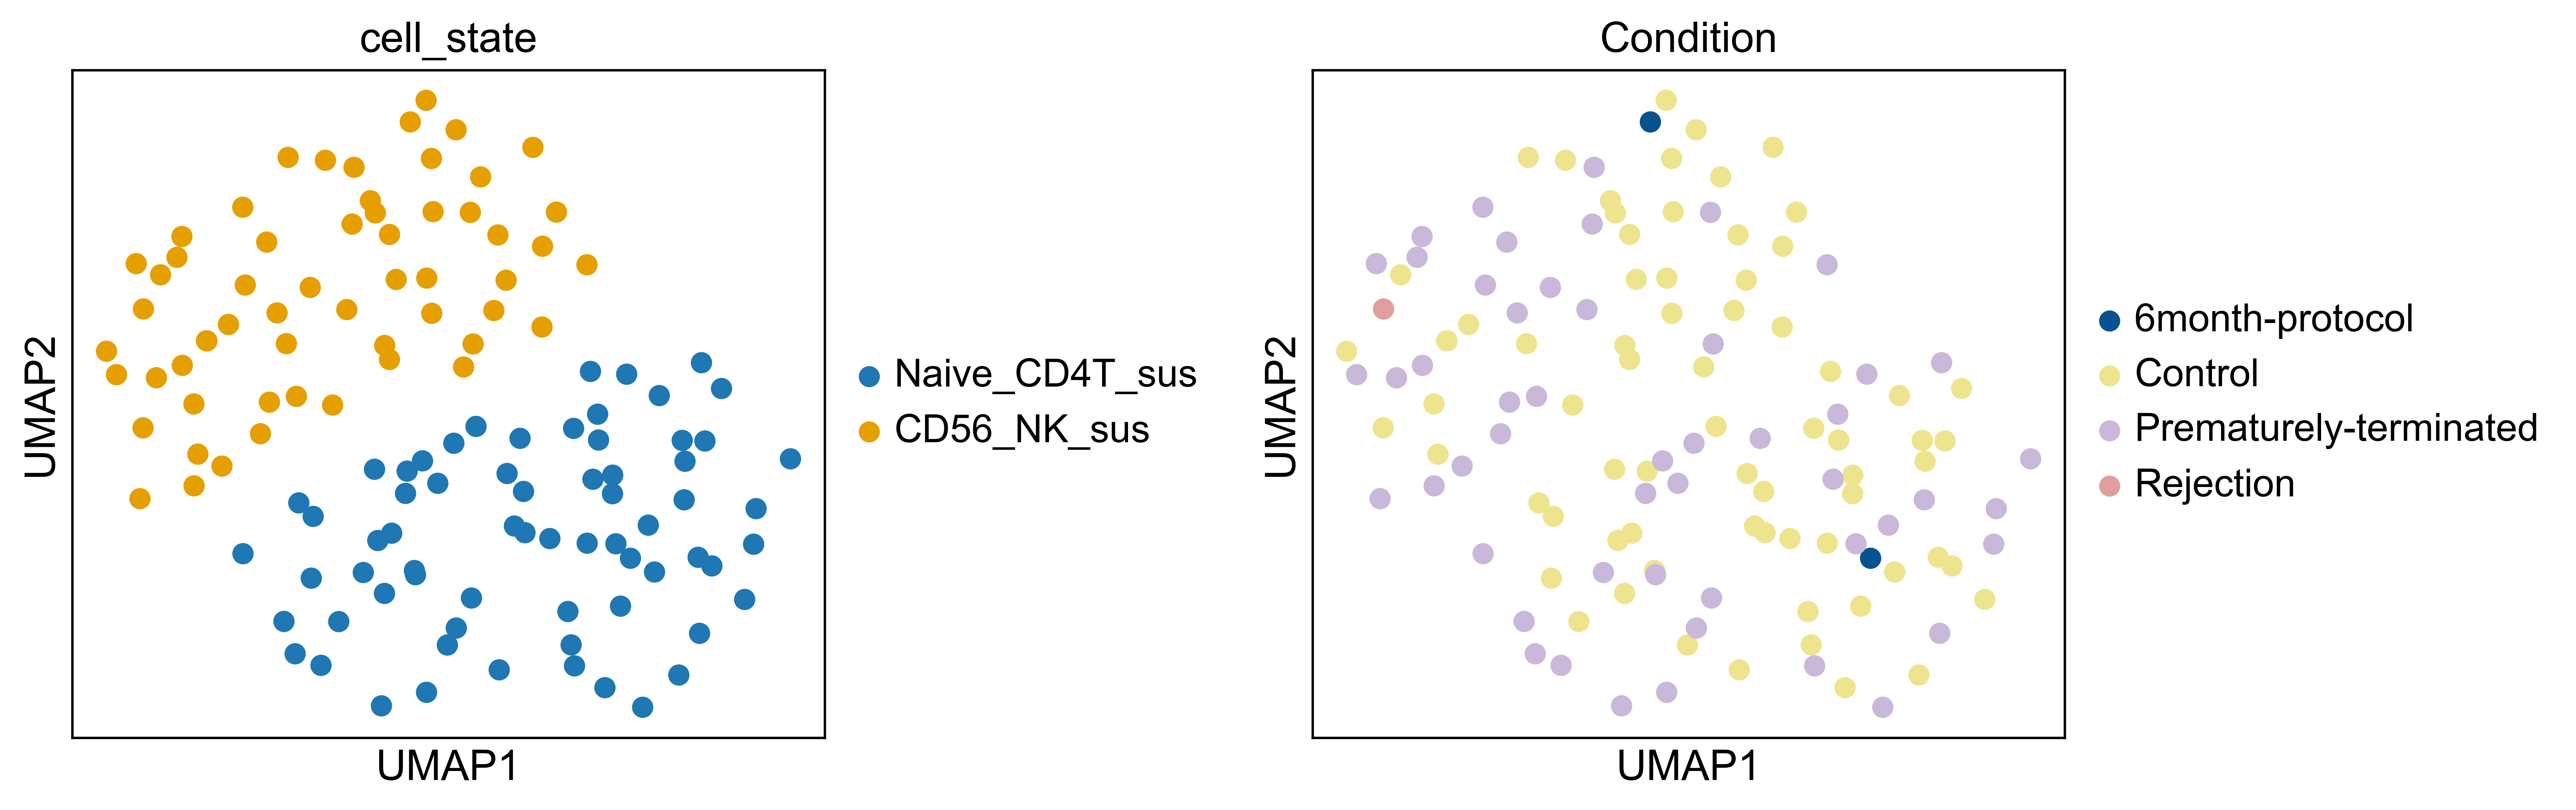

In [14]:

sc.pl.umap( annotated_adata, color=[ 
    # "Condition", 
                                      "cell_state" , 'Condition' ],
            legend_loc="right margin",  size=200, wspace = 0.5, cmap = dimplot_color
)


# Composition

In [17]:
annotated_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/Annotated_Lymph_sus_v5.h5ad')

In [18]:
annotated_adata.obs.Exp

5411-2_CATATCCTCCATAGCA-1    Control
5411-2_ACCTCTTAGTGACCGT-1    Control
5411-2_CTACATAGTGCGTGTC-1    Control
5411-2_TGAGCCACAACTGGGC-1    Control
5411-2_CTTCTAATCATCGTCT-1    Control
                              ...   
PAV88_GGCTTCTCAGCTCTGT-1      p_xHTx
PAV88_AAGGTTAAGGCACGAA-1      p_xHTx
PAV88_CGAGGATGTAATGAGT-1      p_xHTx
PAV88_ATGGAGTAGGAACTAA-1      p_xHTx
PAV89_GCACCAACACTACCAC-1      p_xHTx
Name: Exp, Length: 125, dtype: category
Categories (2, object): ['Control', 'p_xHTx']

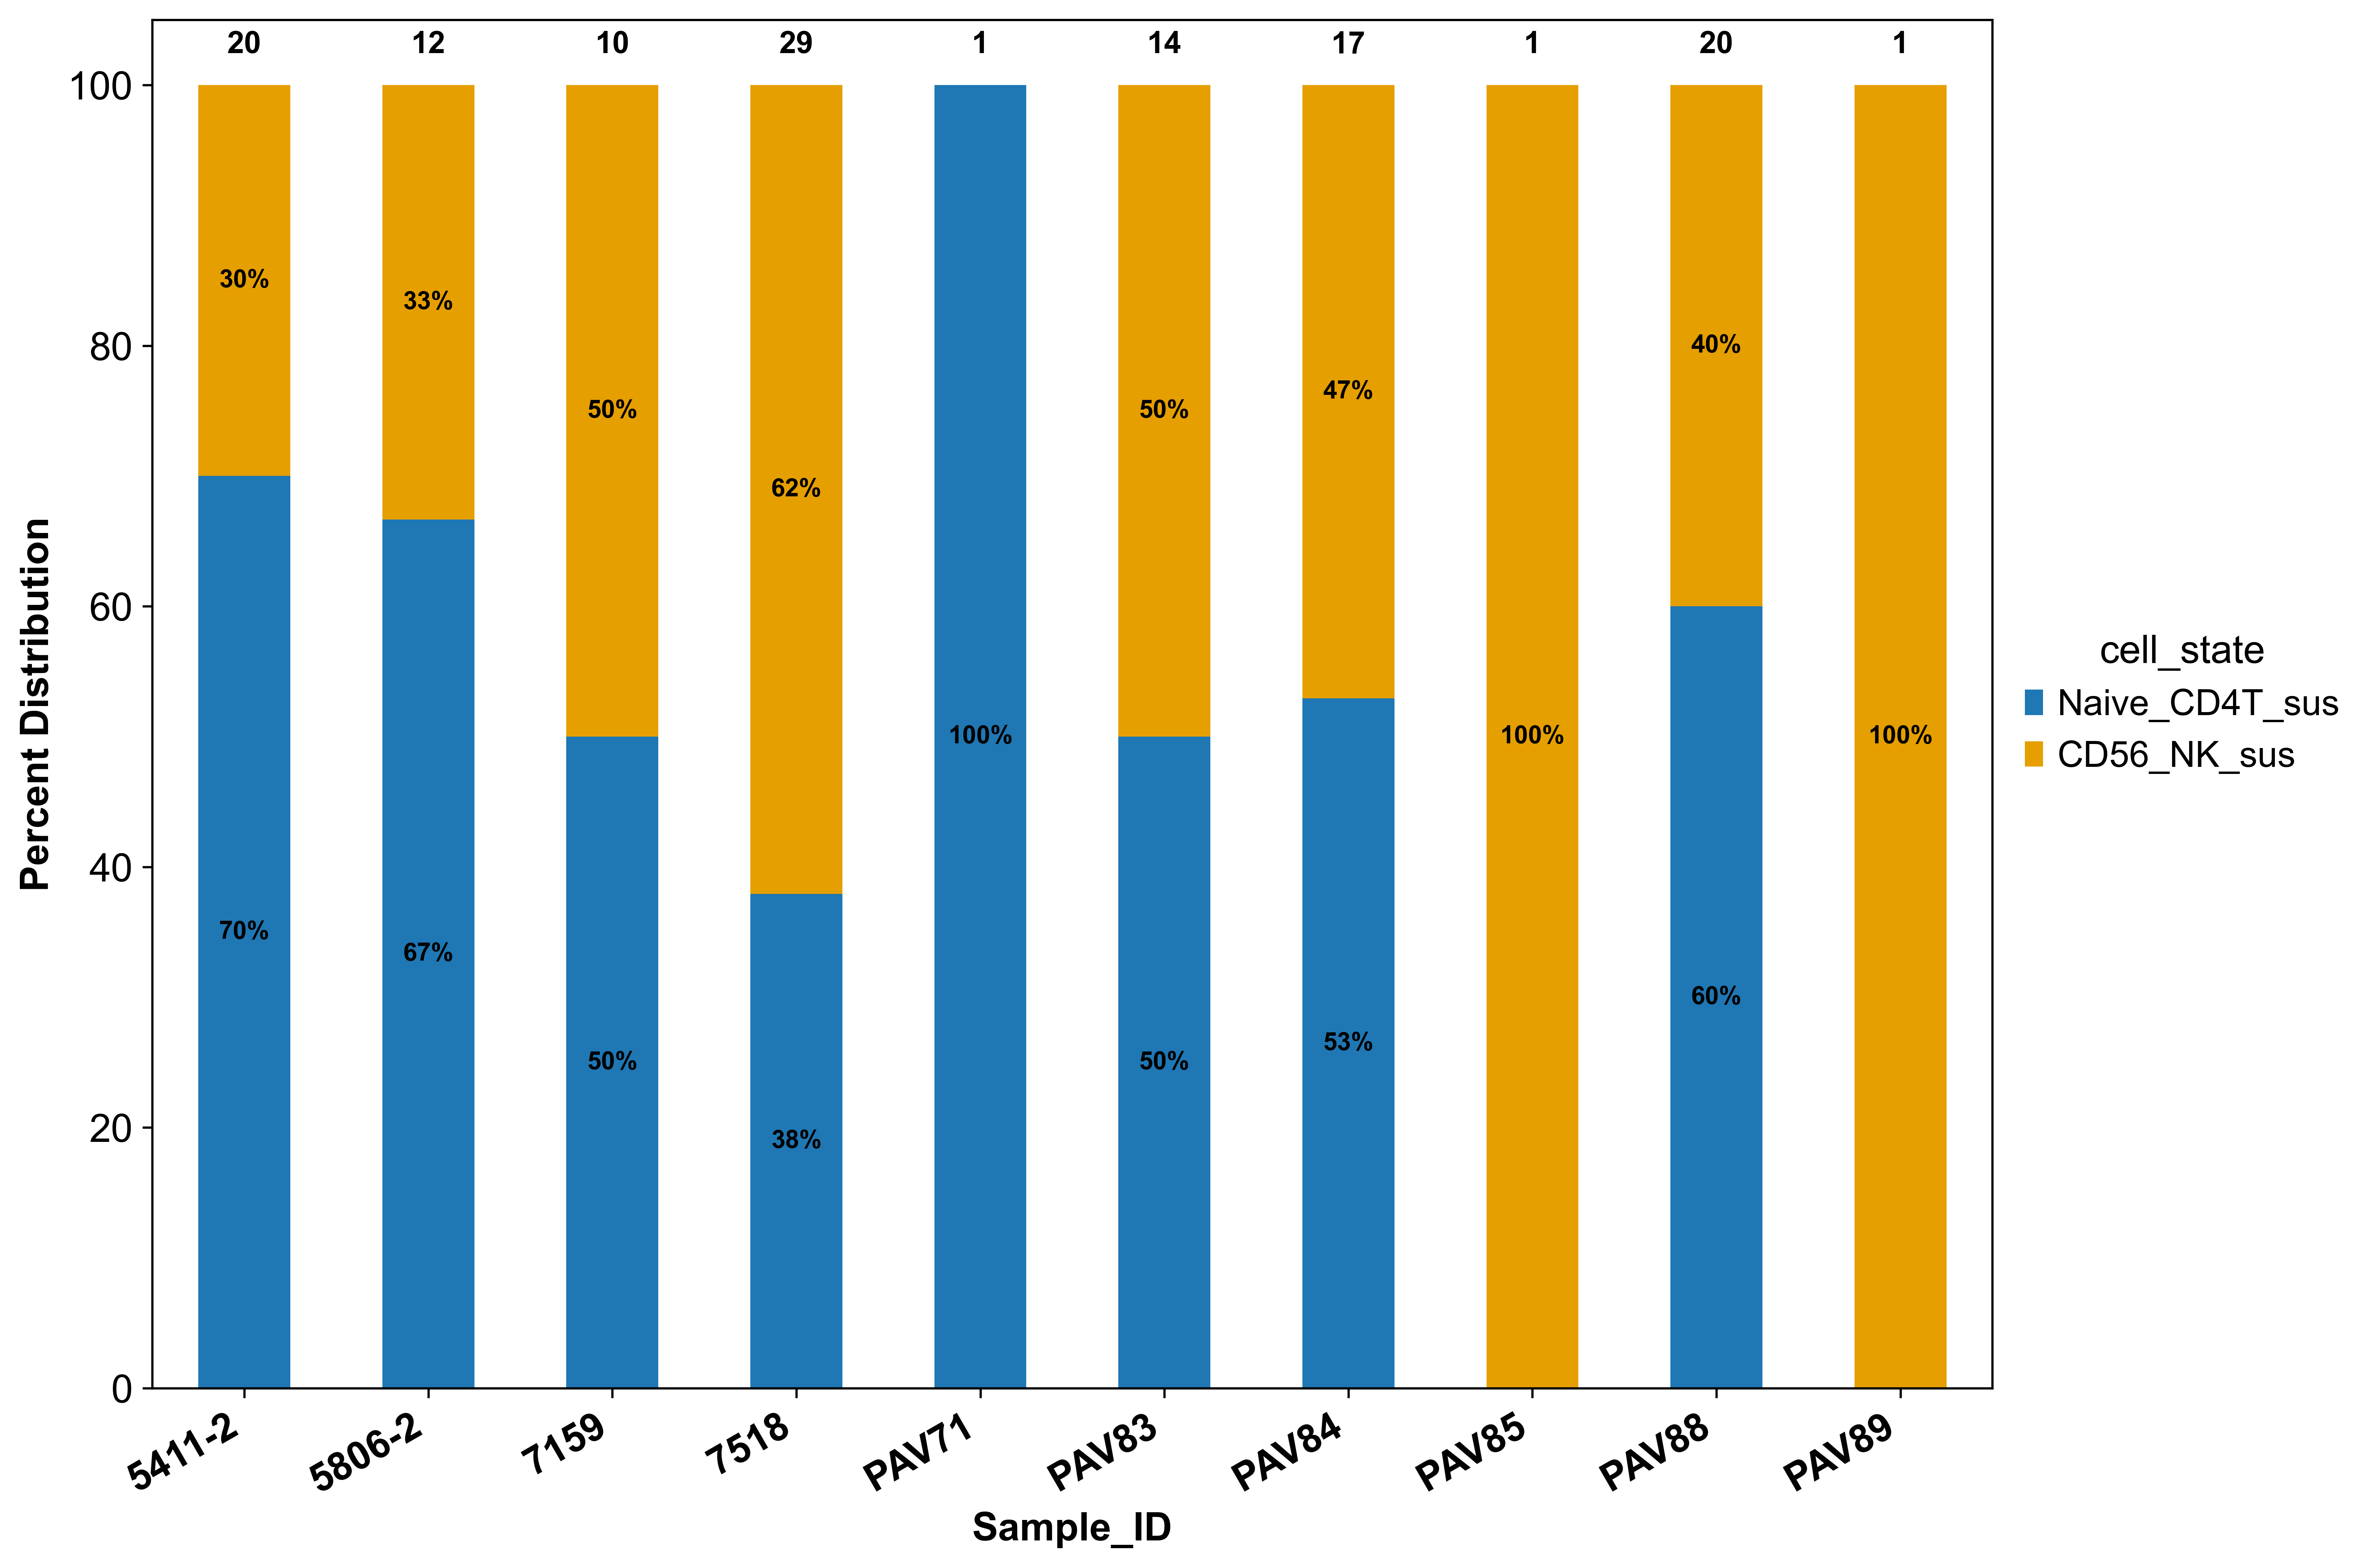

In [19]:
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

def stacked_barplot(adata, xaxis, stack, xaxis_label, legend_label, xaxis_rotation=30, figsize=(8, 6), percent=True):
    
    # 1. Prepare data
    crosstab = pd.crosstab(adata.obs[xaxis], adata.obs[stack])
    # Ensure the order of bars matches the state_order defined in your categorical data
    crosstab = crosstab[adata.obs[stack].cat.categories]
    tmp = crosstab.sum(axis=1)
    ax_data = crosstab.apply(lambda r: r/r.sum()*100, axis=1)
    
    # 2. Get colors from object
    colors = adata.uns.get(f"{stack}_colors", sc.pl.palettes.default_102[:len(ax_data.columns)])
    
    # 3. Plot
    fig, ax = plt.subplots(figsize=figsize)
    ax_plot = ax_data.plot.bar(stacked=True, rot=0, color=colors, ax=ax)
    
    # 4. Labels and Legend
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), title=legend_label, frameon=False)
    plt.xlabel(xaxis_label, fontweight="bold")
    plt.ylabel('Percent Distribution', fontweight="bold")
    
    # 5. Percentage labels inside bars
    if percent:
        for rec in ax_plot.patches:
            height = rec.get_height()
            if height > 3: # Only label if bar is significant
                ax_plot.text(rec.get_x() + rec.get_width() / 2, 
                             rec.get_y() + height / 2, 
                             f"{height:.0f}%",
                             ha='center', va='center', fontsize=9, weight='bold')
    
    # 6. FIX: Pin labels to the center of each bar
    # Get the center positions of the bars
    bar_positions = [patch.get_x() + patch.get_width() / 2 for patch in ax.patches[:len(ax_data.index)]]
    
    ax.set_xticks(bar_positions)
    ax.set_xticklabels(ax_data.index, rotation=xaxis_rotation, ha='right', fontweight='bold')
    
    # Add total cell counts exactly at the top of each bar group
    for i, pos in enumerate(bar_positions):
        ax.text(pos, 102, str(int(tmp.iloc[i])), ha='center', va='bottom', fontsize=11, weight='bold')
    
    ax.grid(False)
    plt.margins(x=0.05) # Add small buffer so labels don't get cut off
    plt.tight_layout()
    plt.show()

# Run the function
stacked_barplot(
    annotated_adata, 
    xaxis='Sample_ID', 
    stack='cell_state', 
    xaxis_label='Sample_ID', 
    legend_label='cell_state', 
    xaxis_rotation=30, 
    figsize=(12, 8), 
    percent=True
)

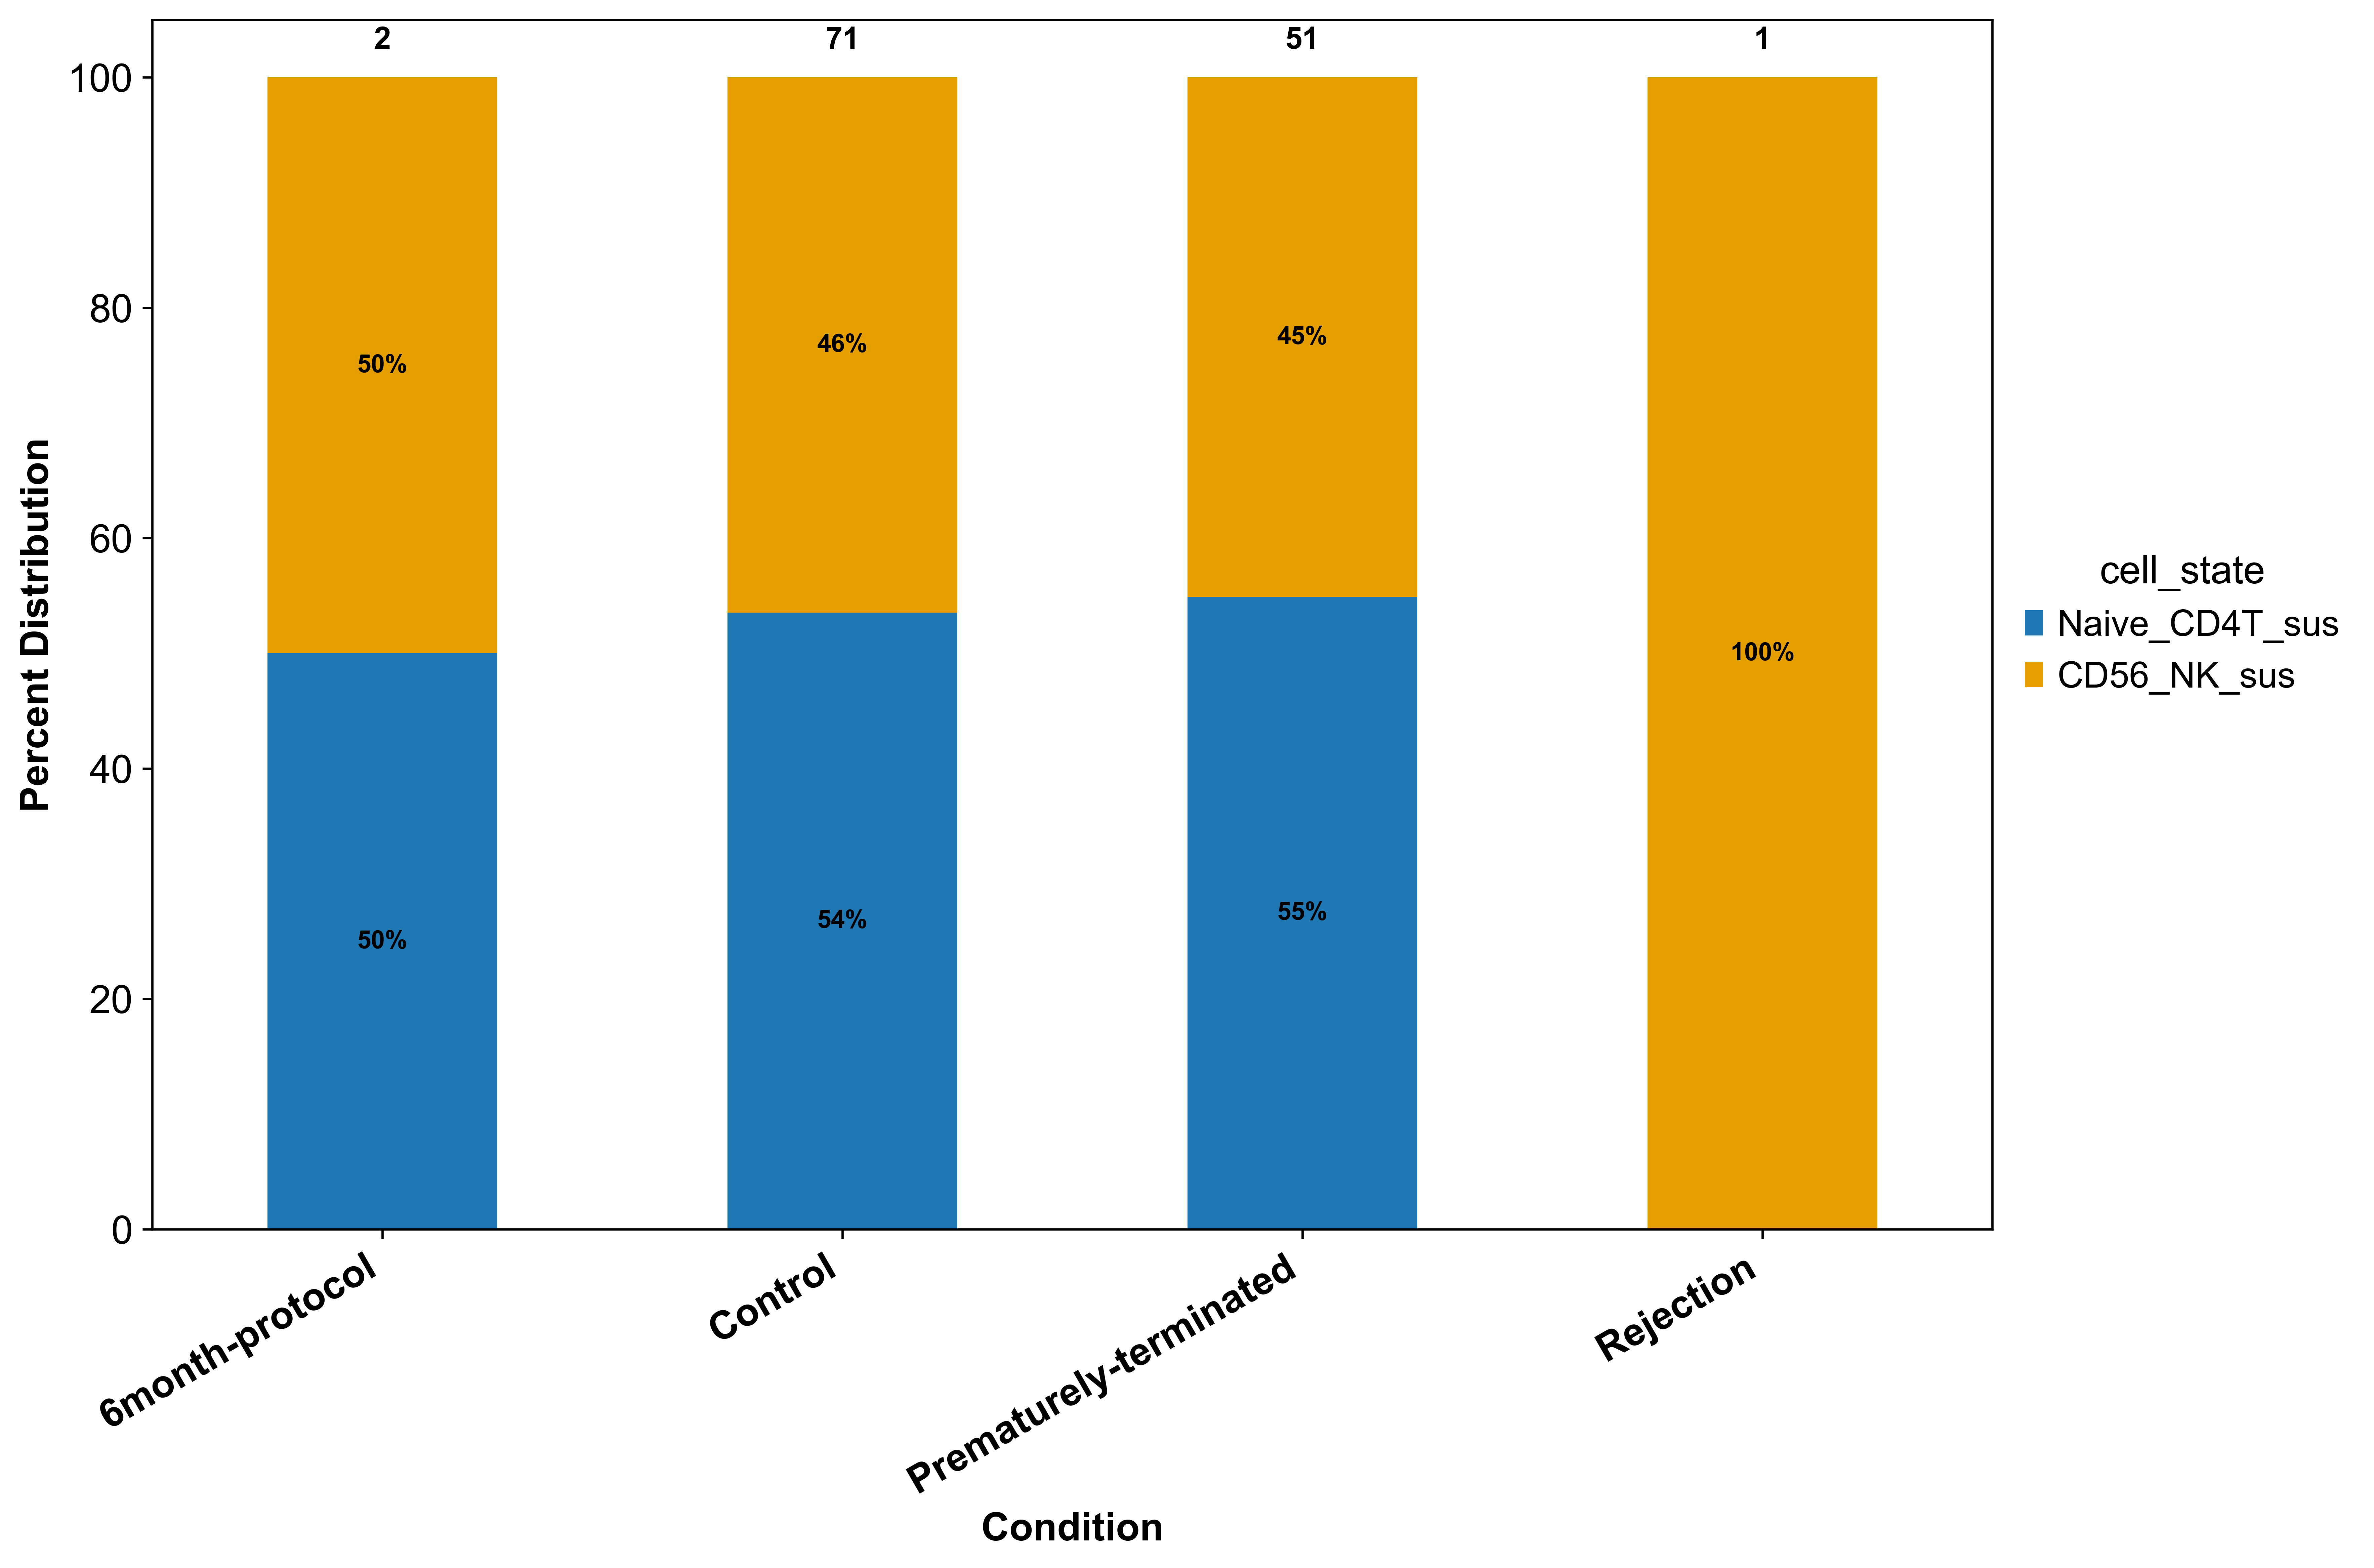

In [20]:
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

def stacked_barplot(adata, xaxis, stack, xaxis_label, legend_label, xaxis_rotation=30, figsize=(8, 6), percent=True):
    
    # 1. Prepare data
    crosstab = pd.crosstab(adata.obs[xaxis], adata.obs[stack])
    # Ensure the order of bars matches the state_order defined in your categorical data
    crosstab = crosstab[adata.obs[stack].cat.categories]
    tmp = crosstab.sum(axis=1)
    ax_data = crosstab.apply(lambda r: r/r.sum()*100, axis=1)
    
    # 2. Get colors from object
    colors = adata.uns.get(f"{stack}_colors", sc.pl.palettes.default_102[:len(ax_data.columns)])
    
    # 3. Plot
    fig, ax = plt.subplots(figsize=figsize)
    ax_plot = ax_data.plot.bar(stacked=True, rot=0, color=colors, ax=ax)
    
    # 4. Labels and Legend
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), title=legend_label, frameon=False)
    plt.xlabel(xaxis_label, fontweight="bold")
    plt.ylabel('Percent Distribution', fontweight="bold")
    
    # 5. Percentage labels inside bars
    if percent:
        for rec in ax_plot.patches:
            height = rec.get_height()
            if height > 3: # Only label if bar is significant
                ax_plot.text(rec.get_x() + rec.get_width() / 2, 
                             rec.get_y() + height / 2, 
                             f"{height:.0f}%",
                             ha='center', va='center', fontsize=9, weight='bold')
    
    # 6. FIX: Pin labels to the center of each bar
    # Get the center positions of the bars
    bar_positions = [patch.get_x() + patch.get_width() / 2 for patch in ax.patches[:len(ax_data.index)]]
    
    ax.set_xticks(bar_positions)
    ax.set_xticklabels(ax_data.index, rotation=xaxis_rotation, ha='right', fontweight='bold')
    
    # Add total cell counts exactly at the top of each bar group
    for i, pos in enumerate(bar_positions):
        ax.text(pos, 102, str(int(tmp.iloc[i])), ha='center', va='bottom', fontsize=11, weight='bold')
    
    ax.grid(False)
    plt.margins(x=0.05) # Add small buffer so labels don't get cut off
    plt.tight_layout()
    plt.show()

# Run the function
stacked_barplot(
    annotated_adata, 
    xaxis='Condition', 
    stack='cell_state', 
    xaxis_label='Condition', 
    legend_label='cell_state', 
    xaxis_rotation=30, 
    figsize=(12, 8), 
    percent=True
)

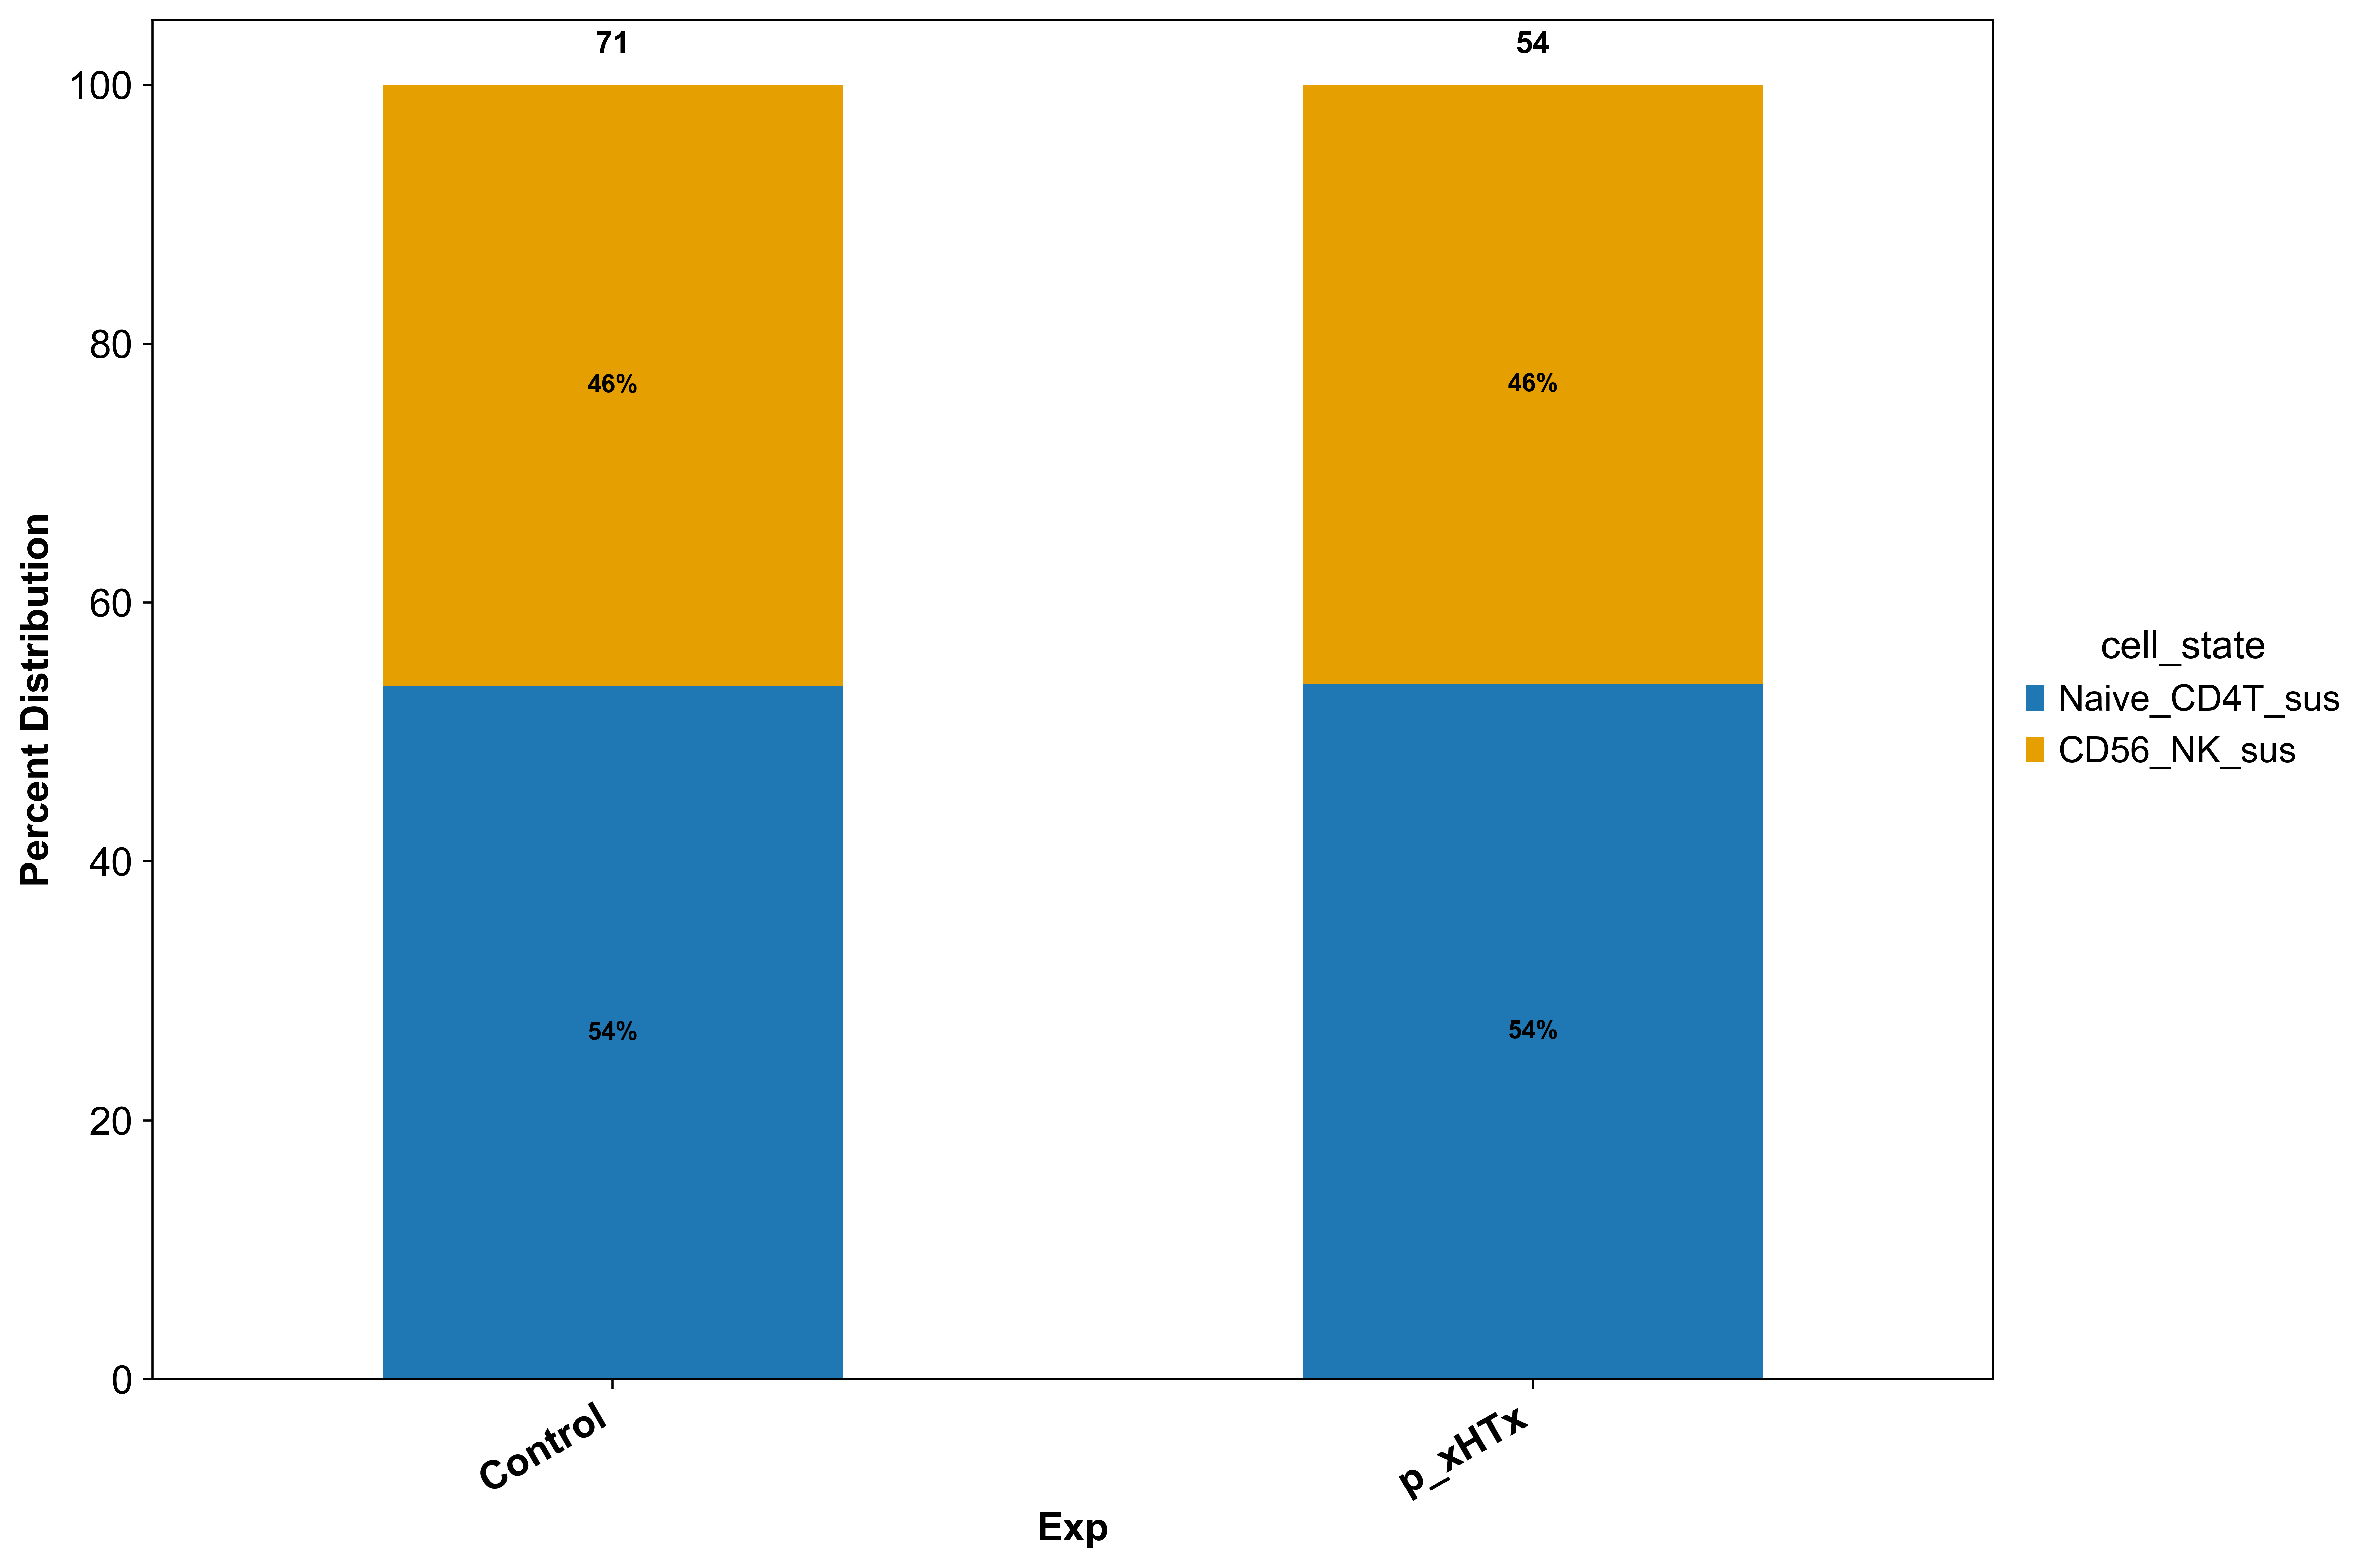

In [21]:
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

def stacked_barplot(adata, xaxis, stack, xaxis_label, legend_label, xaxis_rotation=30, figsize=(8, 6), percent=True):
    
    # 1. Prepare data
    crosstab = pd.crosstab(adata.obs[xaxis], adata.obs[stack])
    # Ensure the order of bars matches the state_order defined in your categorical data
    crosstab = crosstab[adata.obs[stack].cat.categories]
    tmp = crosstab.sum(axis=1)
    ax_data = crosstab.apply(lambda r: r/r.sum()*100, axis=1)
    
    # 2. Get colors from object
    colors = adata.uns.get(f"{stack}_colors", sc.pl.palettes.default_102[:len(ax_data.columns)])
    
    # 3. Plot
    fig, ax = plt.subplots(figsize=figsize)
    ax_plot = ax_data.plot.bar(stacked=True, rot=0, color=colors, ax=ax)
    
    # 4. Labels and Legend
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), title=legend_label, frameon=False)
    plt.xlabel(xaxis_label, fontweight="bold")
    plt.ylabel('Percent Distribution', fontweight="bold")
    
    # 5. Percentage labels inside bars
    if percent:
        for rec in ax_plot.patches:
            height = rec.get_height()
            if height > 3: # Only label if bar is significant
                ax_plot.text(rec.get_x() + rec.get_width() / 2, 
                             rec.get_y() + height / 2, 
                             f"{height:.0f}%",
                             ha='center', va='center', fontsize=9, weight='bold')
    
    # 6. FIX: Pin labels to the center of each bar
    # Get the center positions of the bars
    bar_positions = [patch.get_x() + patch.get_width() / 2 for patch in ax.patches[:len(ax_data.index)]]
    
    ax.set_xticks(bar_positions)
    ax.set_xticklabels(ax_data.index, rotation=xaxis_rotation, ha='right', fontweight='bold')
    
    # Add total cell counts exactly at the top of each bar group
    for i, pos in enumerate(bar_positions):
        ax.text(pos, 102, str(int(tmp.iloc[i])), ha='center', va='bottom', fontsize=11, weight='bold')
    
    ax.grid(False)
    plt.margins(x=0.05) # Add small buffer so labels don't get cut off
    plt.tight_layout()
    plt.show()

# Run the function
stacked_barplot(
    annotated_adata, 
    xaxis='Exp', 
    stack='cell_state', 
    xaxis_label='Exp', 
    legend_label='cell_state', 
    xaxis_rotation=30, 
    figsize=(12, 8), 
    percent=True
)

In [ ]:
cluster_key = 'cell_state'        # or 'FB_clusters' or whatever you used

qc_vars = ['pCMV_____gp07', 'pCMV_____gp14',
           "Sus_scrofa___TOP2A", 
           # 'total_counts', 'percent_mito', 'doublet_score'
          ]

sc.pl.violin(
    annotated_adata,
    qc_vars,
    groupby=cluster_key,
    rotation=90,
    stripplot=False,
    multi_panel=True
)


# DEA annotated

In [22]:
annotated_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/Annotated_Lymph_sus_v5.h5ad')

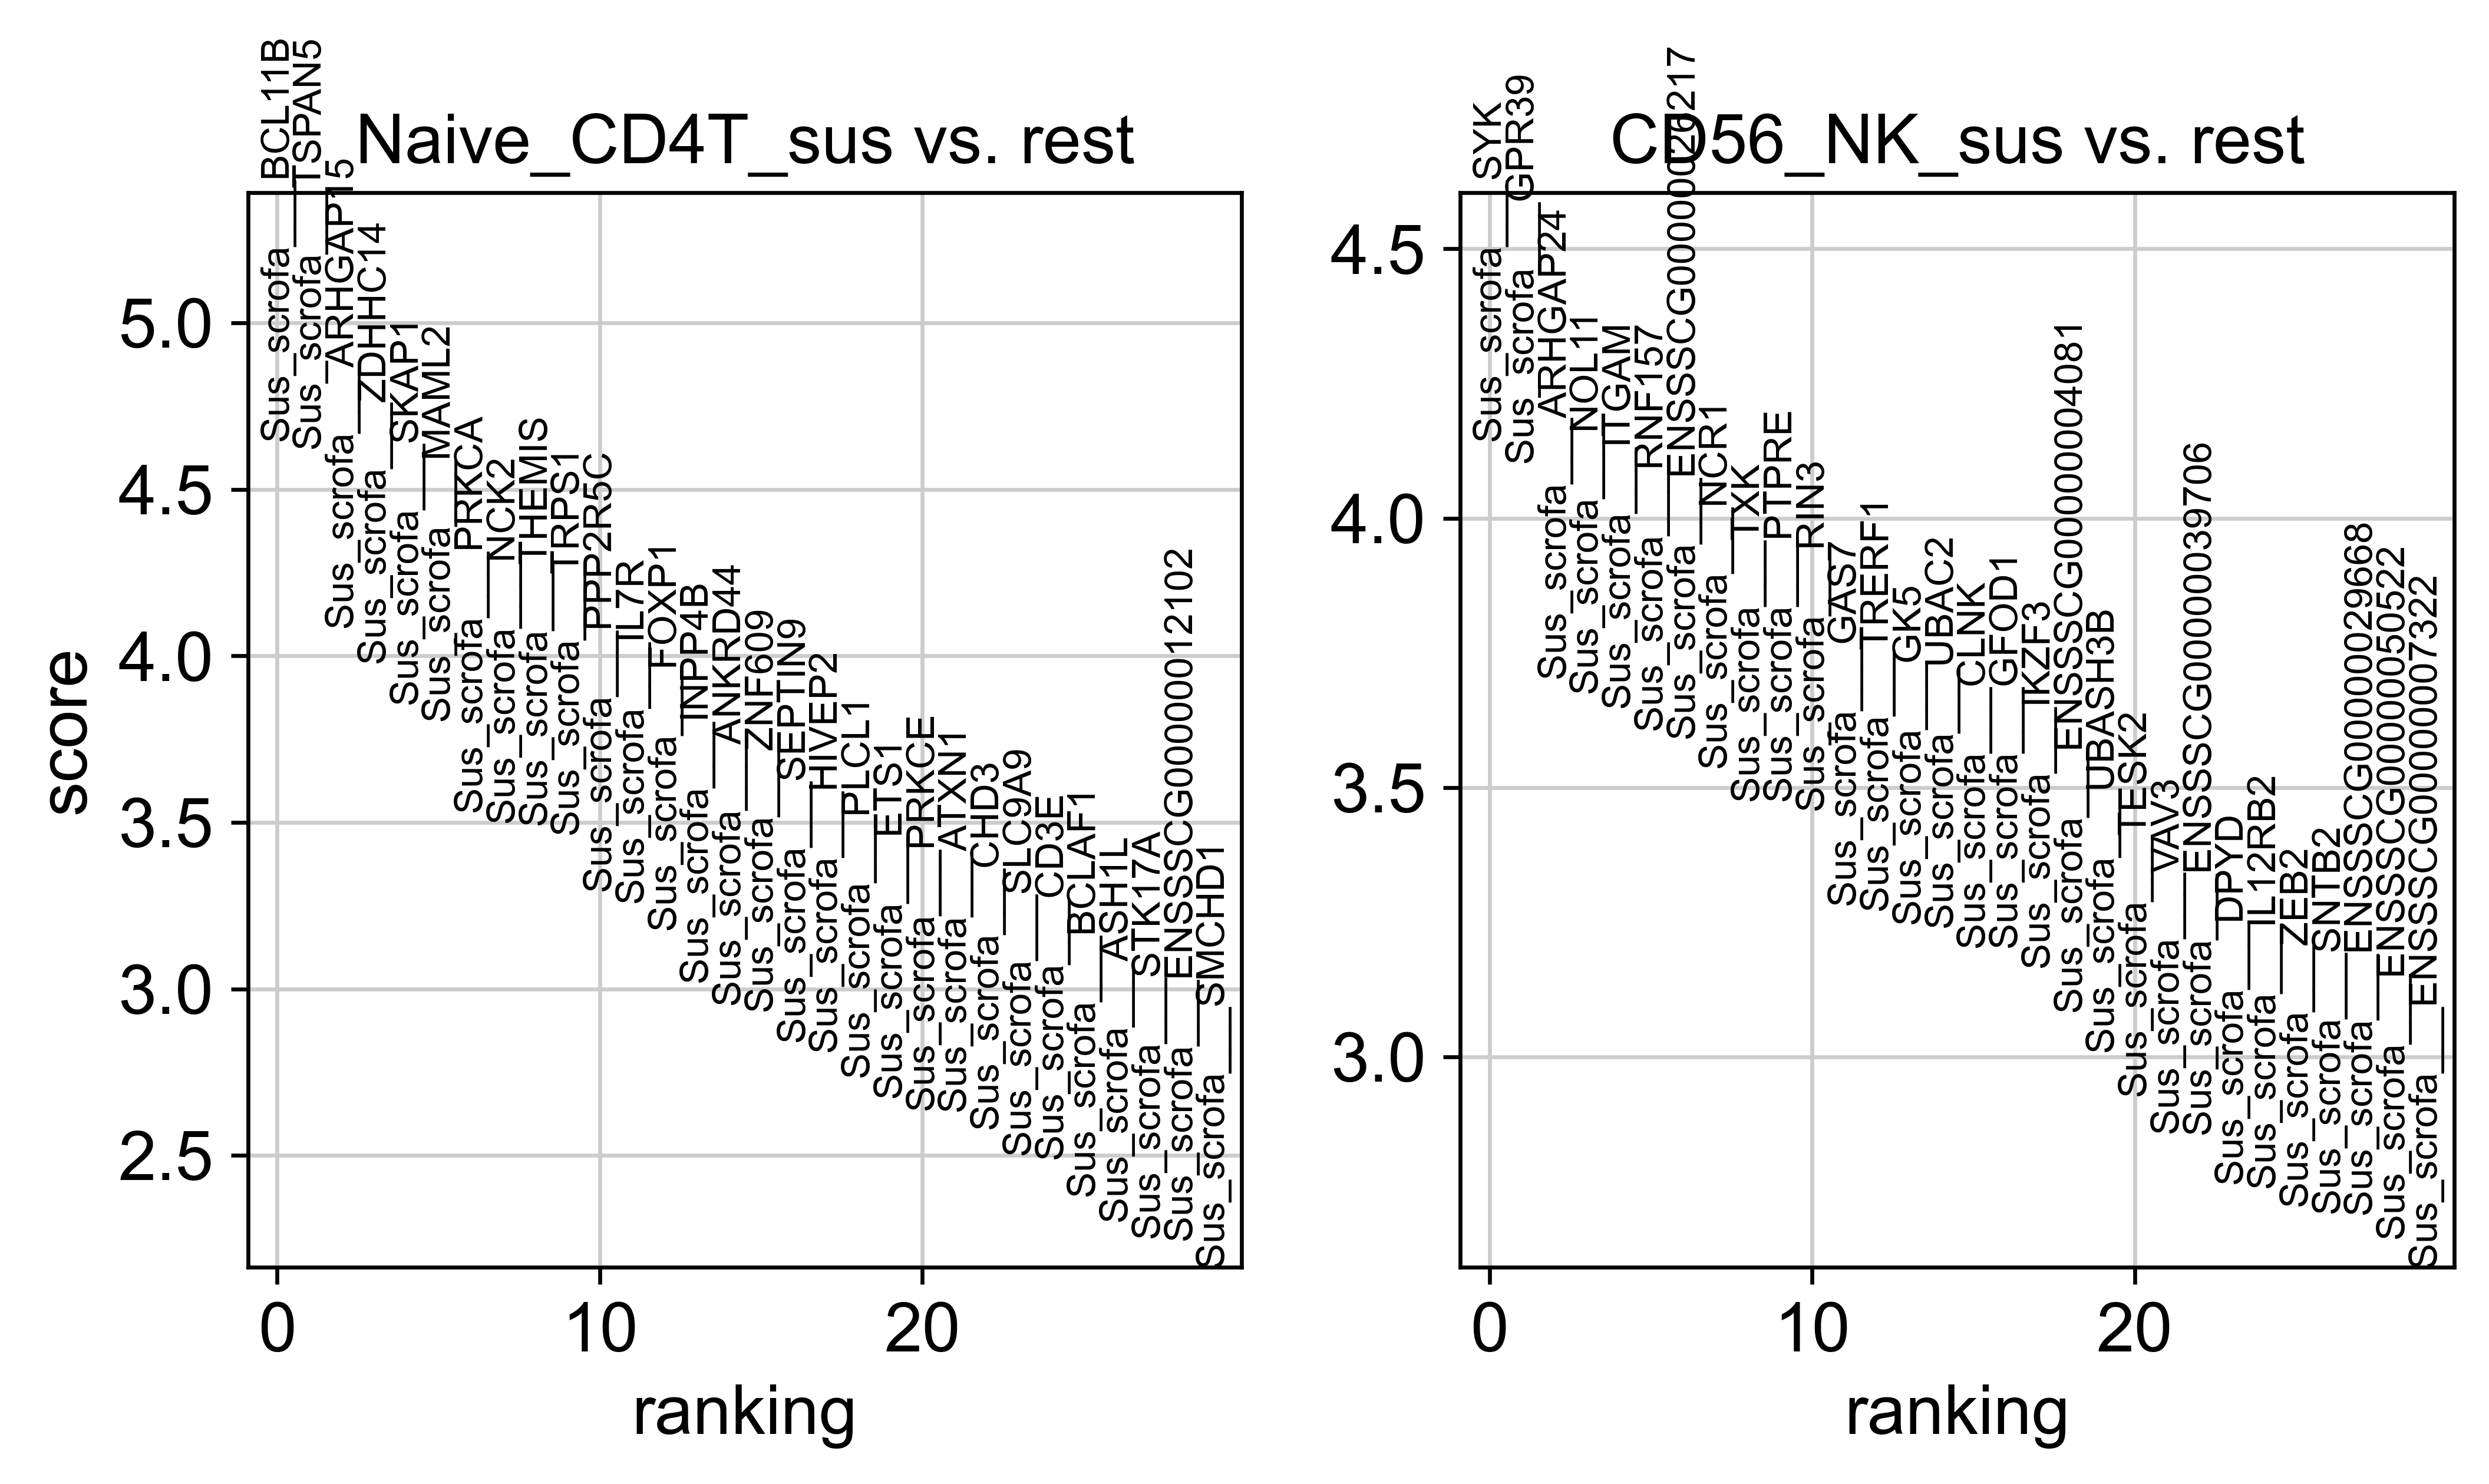

/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [23]:

# Perform differential expressxion to find marker genes for each cluster using Wilcoxon test on raw data
sc.tl.rank_genes_groups(annotated_adata, 'cell_state', method='wilcoxon', key_added='wilcoxon', use_raw=True)

# Visualize the top marker genes for each cluster
sc.pl.rank_genes_groups(annotated_adata, key='wilcoxon', n_genes=30, sharey=False)

# Save the DE analysis to an H5AD file
annotated_adata.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/dea_annotated_Lymph_sus_v5.h5ad')


In [24]:
dea_annotated_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/dea_annotated_Lymph_sus_v5.h5ad')


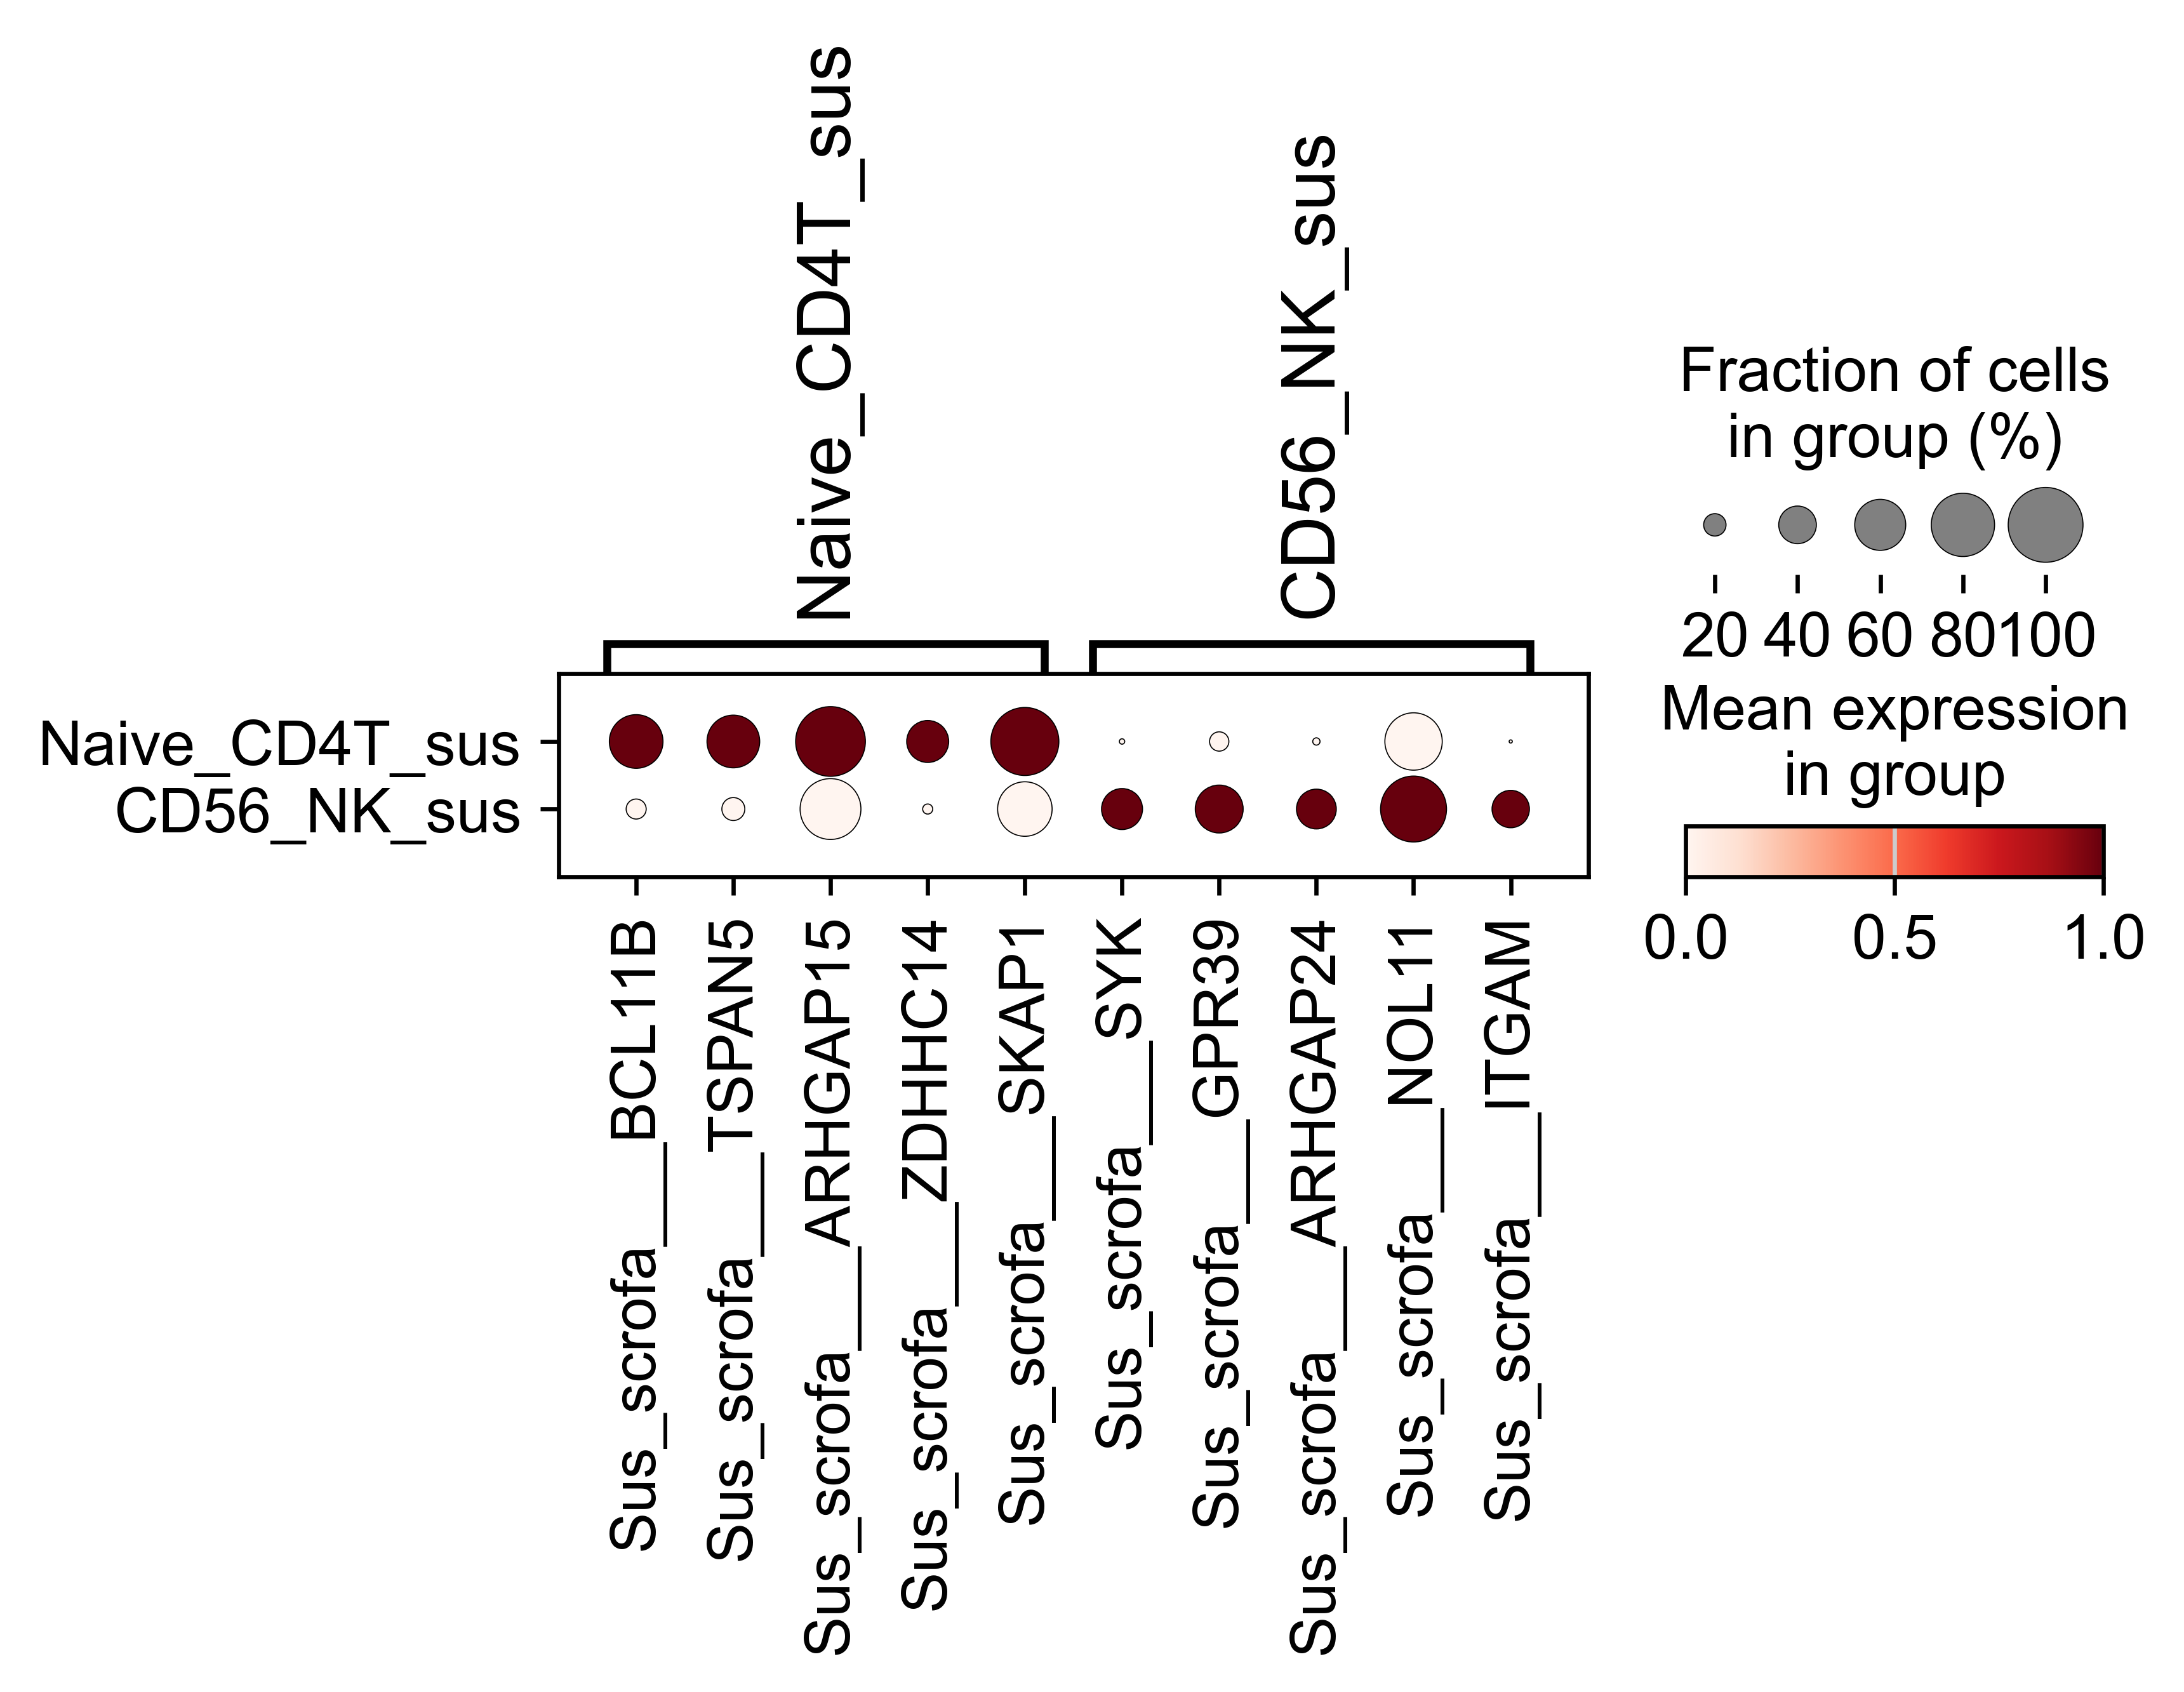

In [25]:
%matplotlib inline

sc.pl.rank_genes_groups_dotplot(dea_annotated_adata, key="wilcoxon", n_genes=5, standard_scale="var"
                                # , cmap="coolwarm", vmin= -1
                               )


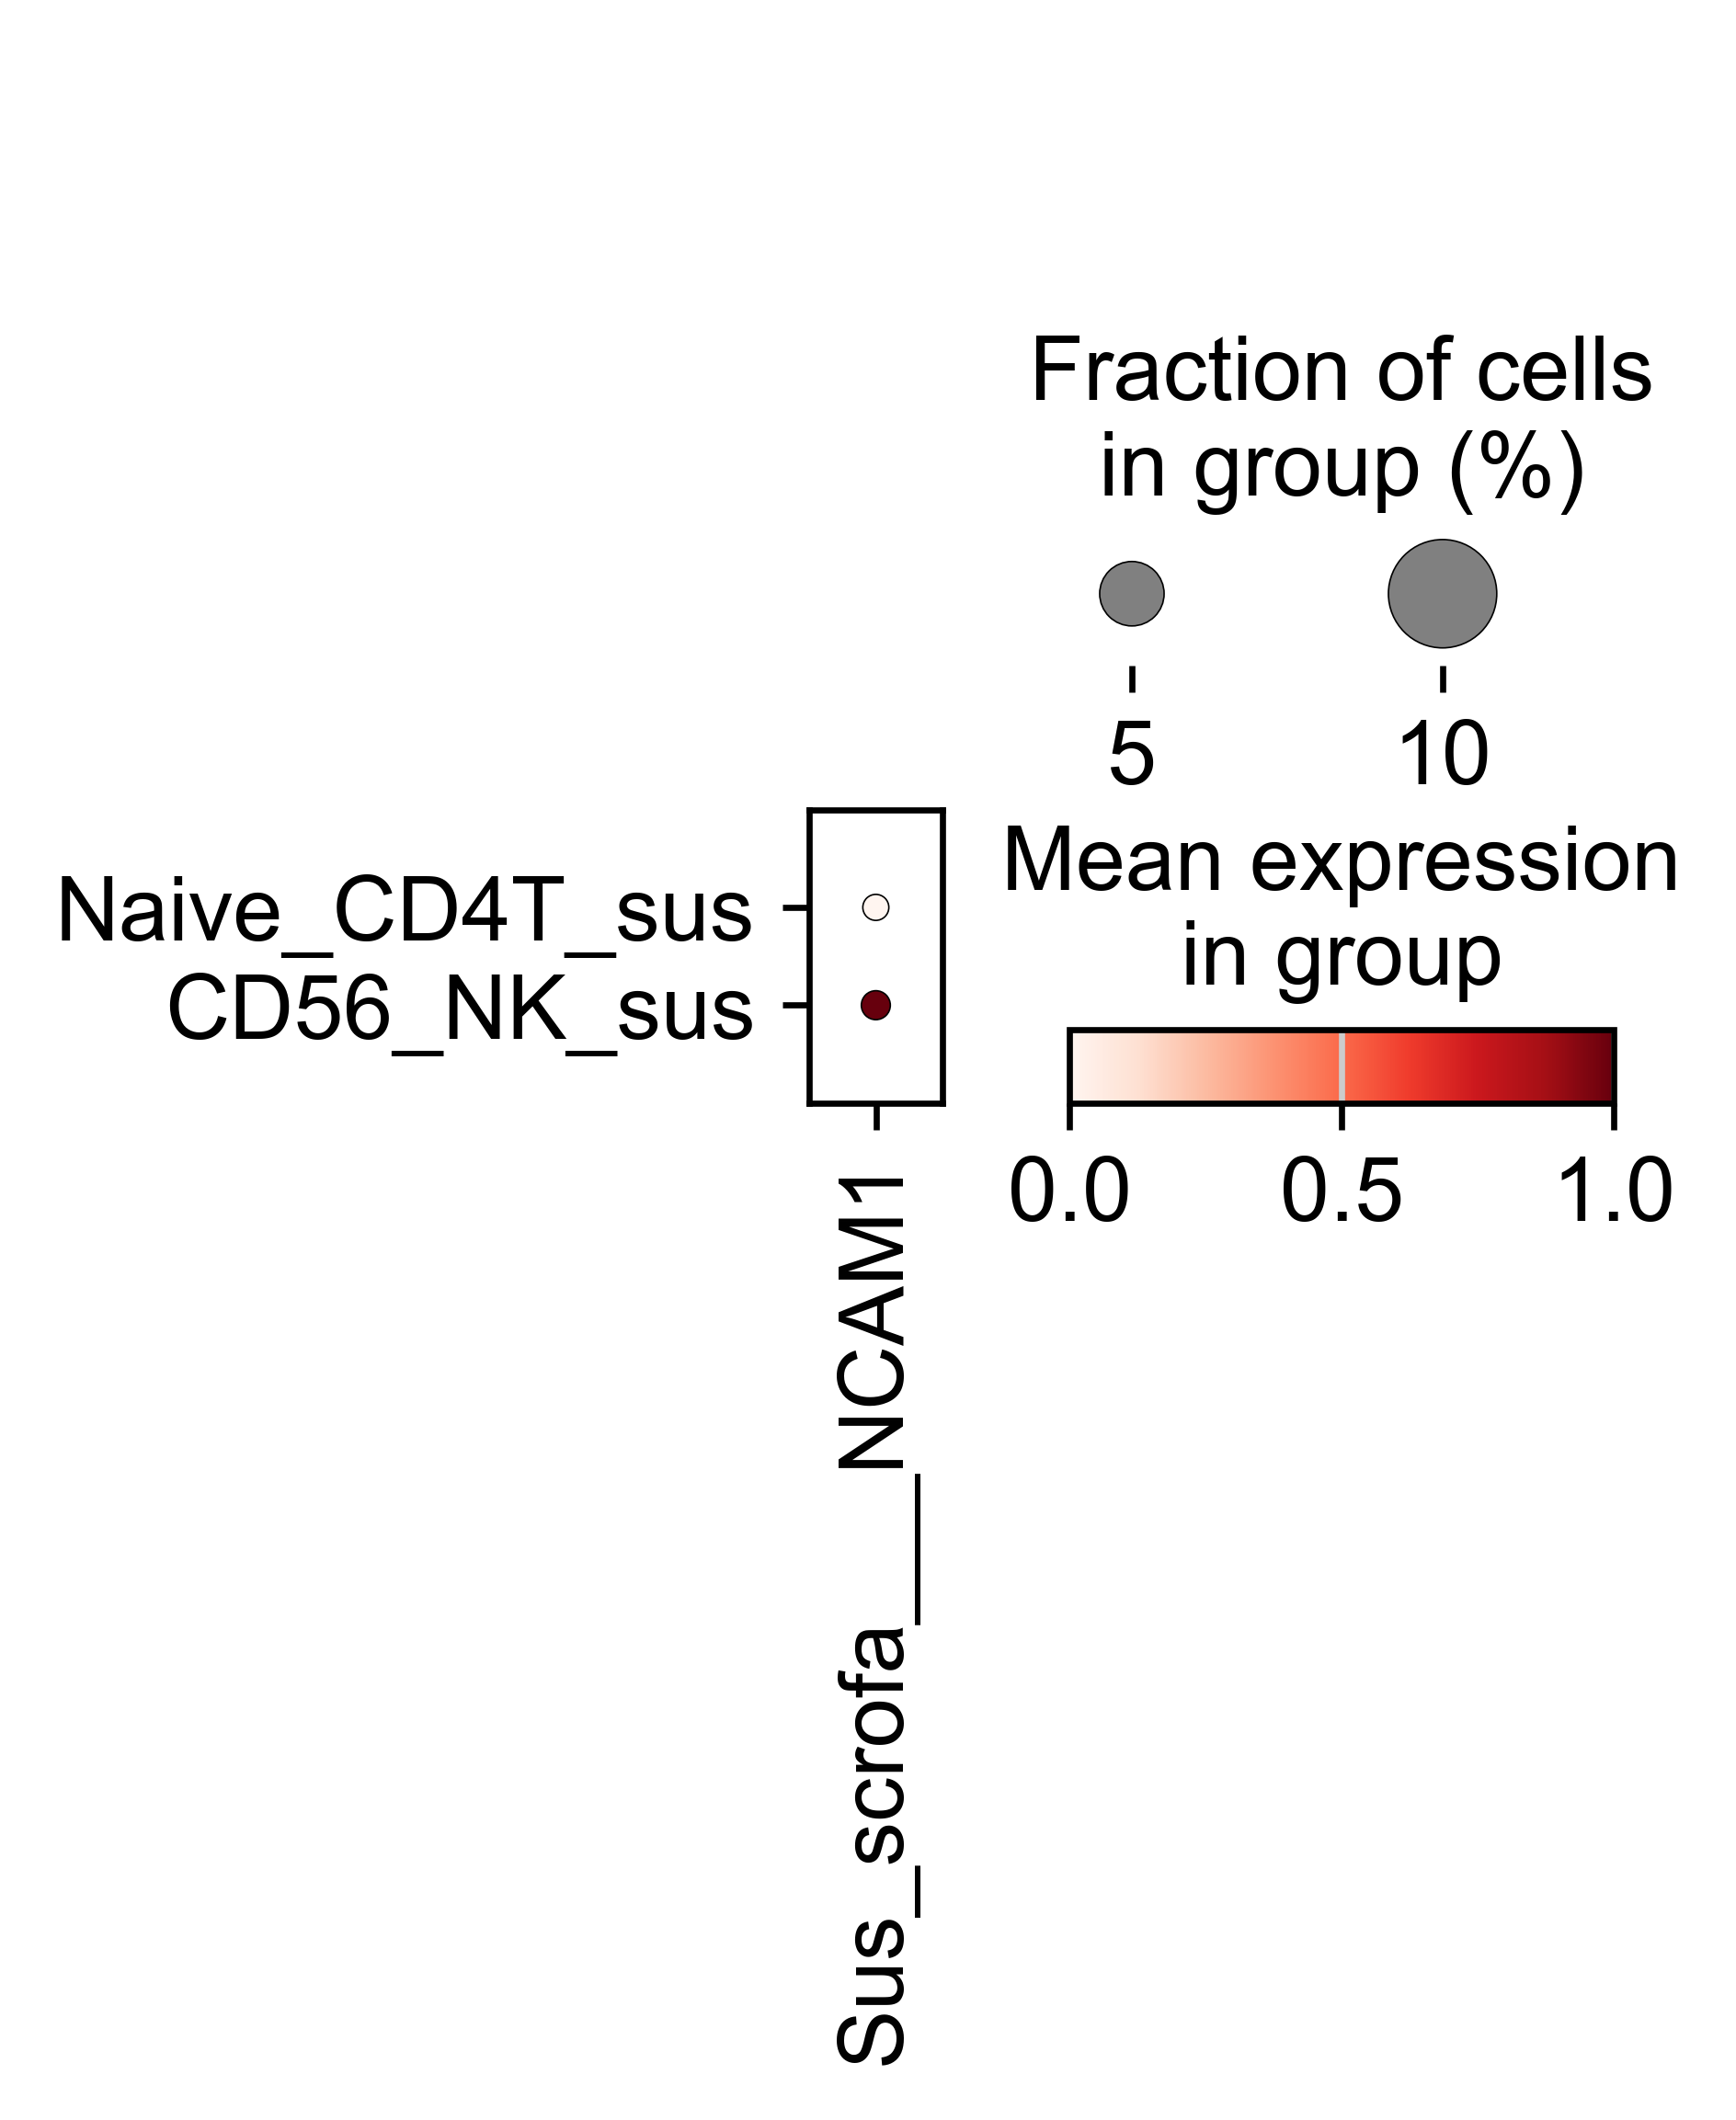

In [26]:
sc.pl.dotplot(
    dea_annotated_adata, 
    var_names=[
        # Lineage Markers
        'Sus_scrofa___NCAM1', 
        # 'Sus_scrofa___IL7R'
    ], 
    groupby='cell_state', 
    standard_scale='var',  # Highly recommended for comparing disparate gene expression ranges
    cmap='Reds', 
    use_raw=True
)

# Final UMAP of lymph_sus

In [2]:
annotated_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/Annotated_Lymph_sus_v5.h5ad')

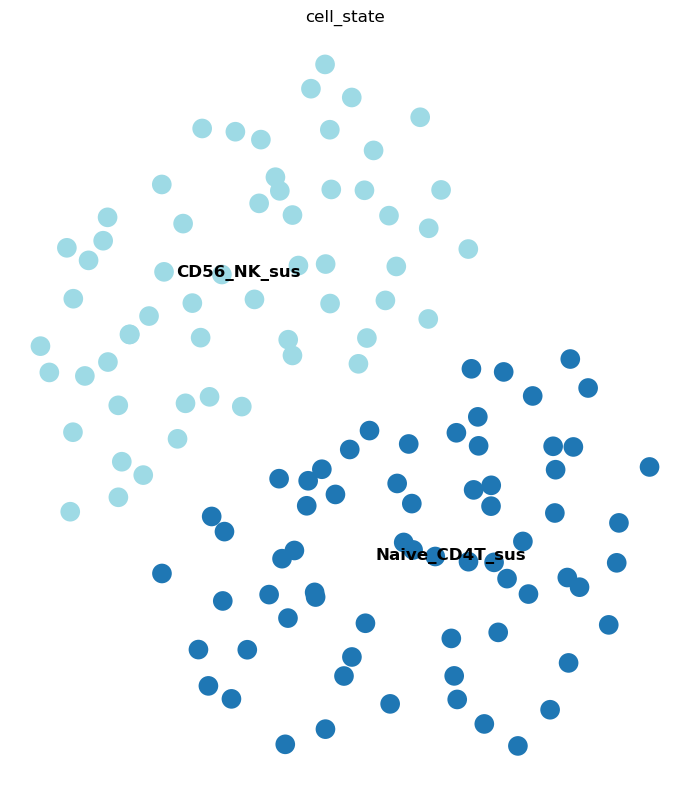

In [5]:
adata = annotated_adata.copy()


fig, ax = plt.subplots(figsize=(7, 8))

sc.pl.umap(
    adata,
    color="cell_state",
    palette="tab20",
    frameon=False,
    legend_loc="on data",
    #legend_fontoutline=0.5,
    size=800,
    legend_fontsize=12,
    ax=ax,
    show=False,
)

# Rasterize the UMAP point cloud to keep the PDF file size manageable
# while axes and on-data labels remain vector-based
ax.set_rasterization_zorder(2)

ax.set_xlabel("UMAP1", fontsize=16, loc="left")
ax.set_ylabel("UMAP2", fontsize=16, loc="bottom")
ax.tick_params(labelbottom=True, labelleft=True, labelsize=14)

plt.tight_layout()

fig.savefig(
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/results/"
    "UMAP_lymph_sus_final.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [27]:
import pandas as pd
import os

de_key = 'wilcoxon'  # The key you used in rank_genes_groups
results = dea_annotated_adata.uns[de_key]
clusters = results['names'].dtype.names  # These are your clusters

output_dir = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/results/Annotated_DEGs"
os.makedirs(output_dir, exist_ok=True)

for clust in clusters:
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    # Optional: Sort by Wilcoxon score, descending (highest first)
    df = df.sort_values('score', ascending=False)
    # Save to CSV
    df.to_csv(f"{output_dir}/Cluster_{clust}_DEGs.csv", index=False)



In [28]:
import os
import pandas as pd

# 1. Setup paths
base_results_dir = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/results/Annotated_DEGs"
sig_output_dir = os.path.join(base_results_dir, "significant_DEGs")
os.makedirs(sig_output_dir, exist_ok=True)

# 2. Thresholds
P_ADJ_CUTOFF = 0.05
LFC_CUTOFF = 0.5

print(f"Filtering DEGs: pval_adj < {P_ADJ_CUTOFF} and |logfoldchange| > {LFC_CUTOFF}")

# 3. Process each cluster's results from your previous loop
# Using the 'clusters' variable from your previous code block
for clust in clusters:
    # Extract data from the scanpy results object
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    # Create the DataFrame
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    
    # 4. Apply strict filtering
    # Filtering for p-adj AND (|LFC| > 0.75)
    sig_df = df[
        (df['pval_adj'] < P_ADJ_CUTOFF) & 
        ((df['logfoldchange'] > LFC_CUTOFF) | (df['logfoldchange'] < -LFC_CUTOFF))
    ].copy()
    
    # Sort by logfoldchange descending
    sig_df = sig_df.sort_values('logfoldchange', ascending=False)
    
    # 5. Save if there are significant genes found
    if not sig_df.empty:
        output_file = f"{sig_output_dir}/Significant_Cluster_{clust}_DEGs.csv"
        sig_df.to_csv(output_file, index=False)
        print(f"  Cluster {clust}: Saved {len(sig_df)} significant DEGs.")
    else:
        print(f"  Cluster {clust}: No genes met the significance criteria.")

print("\nAll significant files saved in:", sig_output_dir)

Filtering DEGs: pval_adj < 0.05 and |logfoldchange| > 0.5
  Cluster Naive_CD4T_sus: No genes met the significance criteria.
  Cluster CD56_NK_sus: No genes met the significance criteria.

All significant files saved in: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/results/Annotated_DEGs/significant_DEGs


# New label transfer with X_UMAP

In [2]:
import os
import scanpy as sc
import pandas as pd

# ---------------------------
# PATHS
# ---------------------------
OBJECTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects"

annotated_adata = sc.read ("/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/Annotated_Lymph_sus_v5.h5ad")

raw_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/cleaned_raw_Lymph_sus_v5.h5ad')

SAVE_PATH = os.path.join(OBJECTS_DIR, "Annotated_Raw_Lymph_sus_preclinical_xeno_v1.h5ad")

print(f"Annotated cells: {annotated_adata.n_obs}")
print(f"Raw cells: {raw_adata.n_obs}")

# ---------------------------
# LABEL TRANSFER
# ---------------------------
# Create a mapping series from the annotated object
label_map = annotated_adata.obs['cell_state']

# Map these to the raw object (this ensures cells align by index)
raw_adata.obs['cell_state'] = raw_adata.obs_names.map(label_map)

# ---------------------------
# UNS TRANSFER
# ---------------------------
# Transfer the color dictionary
if 'cell_state_colors' in annotated_adata.uns:
    raw_adata.uns['cell_state_colors'] = annotated_adata.uns['cell_state_colors']
    print("Transferred cell_state_colors to raw object.")

# ---------------------------
# VALIDATION & FILTERING
# ---------------------------
n_missing = raw_adata.obs['cell_state'].isna().sum()
if n_missing > 0:
    print(f"WARNING: {n_missing} cells in the raw object could not be mapped. Removing them...")
    # Filter out any cells that have NaN in the cell_state column
    raw_adata = raw_adata[raw_adata.obs['cell_state'].notna()].copy()
    print(f"Cells remaining after filter: {raw_adata.n_obs}")
else:
    print("All cells successfully mapped.")

# ---------------------------
# UMAP TRANSFER
# ---------------------------
# We align the UMAP matrix by cell barcodes to ensure perfect mathematical alignment
if 'X_umap' in annotated_adata.obsm:
    # Convert annotated UMAP to a DataFrame indexed by cell barcodes
    umap_df = pd.DataFrame(
        annotated_adata.obsm['X_umap'], 
        index=annotated_adata.obs_names
    )
    
    # Slice the dataframe to match the exact order and composition of the filtered raw object
    aligned_umap = umap_df.loc[raw_adata.obs_names].values
    
    # Assign it safely to the raw object's .obsm
    raw_adata.obsm['X_umap'] = aligned_umap
    print("Transferred UMAP coordinates to raw object.")
else:
    print("WARNING: 'X_umap' not found in annotated_adata.obsm. Skipping UMAP transfer.")

# ---------------------------
# SAVE
# ---------------------------
raw_adata.write(SAVE_PATH)
print(f"\nSaved annotated raw object to: {SAVE_PATH}")

Annotated cells: 125
Raw cells: 125
Transferred cell_state_colors to raw object.
All cells successfully mapped.
Transferred UMAP coordinates to raw object.

Saved annotated raw object to: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/Annotated_Raw_Lymph_sus_preclinical_xeno_v1.h5ad


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [3]:
raw_annotated_lymph_sus = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/Annotated_Raw_FB_preclinical_xeno_v1.h5ad')

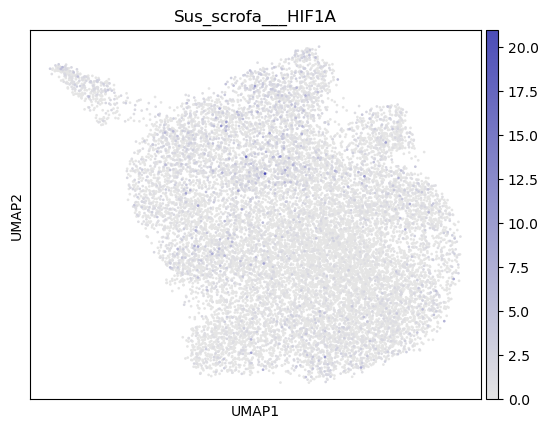

In [4]:
# --- 3. CREATE CUSTOM COLORMAP ---

sc.pl.umap(
    raw_annotated_lymph_sus, 
    color="Sus_scrofa___HIF1A", 
 cmap=dimplot_color,
    size=15,
    legend_loc="right margin"
)

In [2]:
raw_lymph_sus = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Lymph_sus/v5/objects/Raw_annotated_Lymph_sus_v1.h5ad')